In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import nivapy3 as nivapy
import matplotlib.pyplot as plt
import seaborn as sns
import os
import math
import re

# To do

* Generalise so can include additional water chem variables:
  * Units handling (currently only POC dealt with)
  * short_var_name_dict only includes OC vars

Open questions:

* Skienselva - open question whether the data from 1992 are dodgy (step change lower than data from 2000, and gap in between)
* Remove VestfoldLAB data? If so, still need to decide exact period, but perhaps all data?? Or is NIVA lab under-detecting? Implications in terms of dropped sites? Very hard to try and second-guess which lab is more accurately recording the "truth"
* QC of (paired) TOC and DOC: adjust if TOC < DOC fix? E.g. average the two? But only when have paired data...

# Input

In [2]:
# Export date (for reading & writing file names)
export_date = "2026-03"

# Folder where raw (reformatted) data are stored
raw_data_dir = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/intermediate"
fname = f"waterchem_vannmiljo_rivs-lakes_wide_{export_date}.csv"

# Folder to store cleaned data with QC flags
out_dir = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/cleaned"

# Folder to store metadata in
meta_dir = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/metadata"

# Data directory on GitHub (contains e.g. param list)
local_data_dir = r"../../../../data/water_chem"

# Drop data before year
first_year = '1980'

# Water category to keep? Options: "L" (lakes), "R" (rivers)
keep_type = 'R'

# Keep parameters (must match cols present in raw_df)
var_li = ['DOC_mg_l', 'TOC_mg_l']  # 'POC_ug_l', 

# Add in QUANTOM data?
add_quantom = True

In [3]:
raw_df = pd.read_csv(os.path.join(raw_data_dir, fname), parse_dates=['Date'])
raw_df

,WaterLocationCode,lon,lat,WaterCategory,WaterLocationID,Name,Contractor,ActivityName,Date,UpperDepth,...,NA_mg_l,P-ORTO_ug_l,P-PO4_ug_l,P-TDP_ug_l,P-TOT_ug_l,PH,POC_ug_l,SI-SIO2_ug_l,SIO2_ug_l,TOC_mg_l
0,001-100811,11.672260,59.344788,L,100811,Husborn friområde,Haldenvassdraget vannområde,Overvåking av badevann,2024-06-24,0.0,...,NaN,NaN,NaN,NaN,NaN,6.8,NaN,NaN,NaN,NaN
1,001-100811,11.672260,59.344788,L,100811,Husborn friområde,Haldenvassdraget vannområde,Overvåking av badevann,2024-07-25,0.0,...,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN
2,001-100811,11.672260,59.344788,L,100811,Husborn friområde,Haldenvassdraget vannområde,Overvåking av badevann,2025-07-02,0.0,...,NaN,NaN,NaN,NaN,NaN,7.2,NaN,NaN,NaN,NaN
3,001-100812,11.659740,59.377378,L,100812,Ytterbøl senter,Haldenvassdraget vannområde,Overvåking av badevann,2024-06-24,0.0,...,NaN,NaN,NaN,NaN,NaN,6.7,NaN,NaN,NaN,NaN
4,001-100812,11.659740,59.377378,L,100812,Ytterbøl senter,Haldenvassdraget vannområde,Overvåking av badevann,2024-07-25,0.0,...,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
675974,315-48467,11.465823,58.958420,R,48467,"Lille Langvann, utløp",Eurofins Environment Testing Norway (Moss),Lokal overvåking av kalka vassdrag,2024-04-20,0.0,...,5.4,NaN,NaN,NaN,NaN,6.4,NaN,NaN,NaN,NaN
675975,HAV-125308,11.465162,60.115940,R,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-04-07,0.0,...,NaN,47.0,NaN,NaN,73.0,NaN,NaN,NaN,NaN,NaN
675976,HAV-125308,11.465162,60.115940,R,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-05-20,0.0,...,NaN,NaN,NaN,NaN,68.0,NaN,NaN,NaN,NaN,NaN
675977,HAV-125308,11.465162,60.115940,R,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-09-07,0.0,...,NaN,57.0,NaN,NaN,120.0,NaN,NaN,NaN,NaN,8.5


In [4]:
print("Number of sites:", len(raw_df['WaterLocationID'].unique()))
print(raw_df.columns)

Number of sites: 28330
Index(['WaterLocationCode', 'lon', 'lat', 'WaterCategory', 'WaterLocationID',
       'Name', 'Contractor', 'ActivityName', 'Date', 'UpperDepth',
       'LowerDepth', 'CA_mg_l', 'CL_mg_l', 'DOC_mg_l', 'HCO3_mmol_l',
       'N-NH4_ug_l', 'N-NO3_ug_l', 'N-SNOX_ug_l', 'N-TOT_ug_l', 'NA_mg_l',
       'P-ORTO_ug_l', 'P-PO4_ug_l', 'P-TDP_ug_l', 'P-TOT_ug_l', 'PH',
       'POC_ug_l', 'SI-SIO2_ug_l', 'SIO2_ug_l', 'TOC_mg_l'],
      dtype='object')


# Select data (chem vars of interest, rivers), average over depth, do a first tidy

For rivers, a lot of the local monitoring of limed rivers seems to sample from two different depths for the same river/date. From a quick look, the TOC values look very similar across the two depths, so decide to average over them. 

In all, there are ~270 rows where the upper depth > 1, and 22600'ish where it is > 0.5 m.

Here, we drop upper and lower depth and then average over the remaining metadata columns.

In [5]:
meta_cols_full = [
    'WaterLocationCode', 'lon', 'lat', 'WaterLocationID',
    'Name', 'Contractor', 'ActivityName', 'Date', 'UpperDepth',
    'LowerDepth']

meta_cols_no_depth = [
    'WaterLocationCode', 'lon', 'lat', 'WaterLocationID',
    'Name', 'Contractor', 'ActivityName', 'Date']

# Drop lakes, all chem aside from desired vars and all data before 1980
first_tidy_df = raw_df.loc[(raw_df['WaterCategory'] == keep_type) & (raw_df['Date'] > first_year), meta_cols_no_depth + var_li]
print("Original number of rows:", len(first_tidy_df))

# Drop rows where all data cols are NaNs
first_tidy_df = first_tidy_df.dropna(subset=var_li, how='all')
print("Rows after dropping lakes, data before 1980 and all NaNs for var_li:", len(first_tidy_df))

# Average over depth
first_tidy_df = first_tidy_df.groupby(meta_cols_no_depth, as_index=False)[var_li].mean()

# Convert units of POC to be same as other C species
# N.B. need more general way of doing this if include other vars
if 'POC_ug_l' in var_li:
    # Convert units from ug/l to mg/l
    first_tidy_df['POC_mg_l'] = df['POC_ug_l'] * 0.001
    # Fix negatives
    first_tidy_df.loc[first_tidy_df['POC_mg_l'] < 0, 'POC_mg_l'] = 0
    # Drop original column
    first_tidy_df = first_tidy_df.drop('POC_ug_l', axis=1)

    # Update var_li
    var_li = [v if v != 'POC_ug_l' else 'POC_mg_l' for v in var_li]

short_var_name_dict = {
    'DOC_mg_l': 'DOC',
    'POC_mg_l': 'POC',
    'TOC_mg_l': 'TOC'
}

print("Final number of rows, after averaging over depth:", len(first_tidy_df))
print("Number of sites:", len(first_tidy_df['WaterLocationID'].unique()))
first_tidy_df

Original number of rows: 427724
Rows after dropping lakes, data before 1980 and all NaNs for var_li: 185410
Final number of rows, after averaging over depth: 184232
Number of sites: 11028


,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor,ActivityName,Date,DOC_mg_l,TOC_mg_l
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2011-09-15,NaN,10.61
1,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2012-10-09,NaN,9.96
2,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2013-08-27,NaN,9.39
3,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2014-08-19,NaN,7.46
4,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2015-08-28,NaN,8.40
...,...,...,...,...,...,...,...,...,...,...
184227,314-89994,11.771138,59.773726,89994,"Store Lyseren, utløp",NIVA,Økosystemovervåkning i ferskvann (ØkoFersk),2011-10-13,NaN,4.70
184228,315-48068,11.464094,58.897006,48068,"Årbutjernet, utløp",NIVA,Lokal overvåking av kalka vassdrag,2011-10-31,NaN,11.00
184229,315-48338,11.468447,58.956903,48338,Hestetjern,NIVA,Lokal overvåking av kalka vassdrag,2011-10-29,NaN,21.20
184230,HAV-125308,11.465162,60.115940,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-09-07,NaN,8.50


In [6]:
first_tidy_df[var_li].describe()

,DOC_mg_l,TOC_mg_l
count,10296.000000,181943.000000
mean,4.516054,6.844495
std,5.979668,65.194425
min,0.000000,0.000000
25%,1.500000,2.800000
50%,3.200000,4.700000
75%,5.800000,7.500000
max,390.000000,12000.000000


So we have over 180 000 TOC samples, only 10 000'ish DOC samples, and 4000 POC samples. Probably drop POC? Yes.

# Make stn_df and calculate metadata on raw water chem

Do this now to help with QC'ing later.

NOTE: rough code! Needs tidying and then probably moving out to a separate .py file, as it detracts from here (and is likely to be used across notebooks).

In [7]:
site_df_cols = ['WaterLocationCode', 'lon', 'lat', 'WaterLocationID', 'Name']  # Just ID and location, activity name and contractor change over time
raw_stn_df = first_tidy_df[site_df_cols].drop_duplicates()
raw_stn_df

,WaterLocationCode,lon,lat,WaterLocationID,Name
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA
14,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA
28,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN
32,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE"
37,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN
...,...,...,...,...,...
184225,314-62046,11.730778,59.479630,62046,Håbyelva
184227,314-89994,11.771138,59.773726,89994,"Store Lyseren, utløp"
184228,315-48068,11.464094,58.897006,48068,"Årbutjernet, utløp"
184229,315-48338,11.468447,58.956903,48338,Hestetjern


## First and last years with data

In [8]:
# Dataframe of start & end dates
def start_end_dates_df(df, meta_cols):

    # Create a copy of the dataframe to avoid changing the original data
    wc_dates_df = df.copy().sort_values('Date')

    # for each col, if it's NaN, keep as NaN. Otherwise, replace with the sampling date
    for col in wc_dates_df.columns:
        if col not in meta_cols:
            wc_dates_df[col] = np.where(wc_dates_df[col].isna(), np.nan, wc_dates_df['Date'].astype(str))
            wc_dates_df[col] = pd.to_datetime(wc_dates_df[col])

    wc_dates_df = wc_dates_df[['WaterLocationCode', 'Name'] + var_li]  # just keep station_name, station_id

    # Get the first non-NaN 'sample_date' for each 'station_id' and each data column
    start_date_df = wc_dates_df.groupby('WaterLocationCode').min()
    end_date_df = wc_dates_df.groupby('WaterLocationCode').max()

    return(start_date_df, end_date_df)


start_date_df, end_date_df = start_end_dates_df(first_tidy_df, meta_cols_no_depth)
print(start_date_df.head())

                                   Name DOC_mg_l   TOC_mg_l
WaterLocationCode                                          
001-119928          Oppstrøms Bommen RA      NaT 2011-09-15
001-119929          Nedstrøms Bommen RA      NaT 2011-09-15
001-30653           YSTE YSTEHEDEBEKKEN      NaT 1987-03-23
001-30683          Unnebergbekken, UNNE      NaT 1987-03-23
001-30687                 ØRB2 ØRBEKKEN      NaT 1991-05-27


In [9]:
def make_n_years_df(start_date_df, end_date_df):
    # Only consider datetime columns
    dt_cols = [col for col in start_date_df.columns 
               if pd.api.types.is_datetime64_any_dtype(start_date_df[col])]

    # earliest sample date per station
    first_dates = start_date_df[dt_cols].min(axis=1)
    last_dates = end_date_df[dt_cols].max(axis=1)

    # extract years
    start_year_s = first_dates.dt.year
    start_year_s.name = 'start_year'
    
    end_year_s = last_dates.dt.year
    end_year_s.name = 'end_year'
    
    year_df = pd.concat([start_year_s, end_year_s], axis=1)
    
    year_df['n_years'] = (year_df['end_year'] - year_df['start_year']) + 1

    return year_df, start_year_s, end_year_s


year_df, start_year_s, end_year_s = make_n_years_df(start_date_df, end_date_df)
year_df.describe()

,start_year,end_year,n_years
count,11028.000000,11028.000000,11028.000000
mean,2014.640551,2019.188792,5.548241
std,8.666410,6.904345,6.942060
min,1980.000000,1983.000000,1.000000
25%,2011.000000,2017.000000,1.000000
50%,2017.000000,2021.500000,2.000000
75%,2021.000000,2024.000000,8.000000
max,2025.000000,2026.000000,45.000000


## Length of record

Work out number of years with data rougly as the difference between the start and end date. **Note: doesn't take data gaps into account**. Capture that in the next section by looking at the number of points per site

Note: in n_years_df, 0 means no years of data but that there is one data point. NaN means no data at all.

In [10]:
def calculate_record_length(end_date_df, start_date_df):
    # Work out number of years with data per site and variable
    duration_df = end_date_df[var_li] - start_date_df[var_li]
    n_years_df = duration_df.apply(lambda x: x.dt.days / 365.25)
    
    # Round values >1 up to 1 year, i.e. assume 1 full year per site with data.
    # Otherwise, if have just 2 samples collected 2 weeks apart, the estimated
    # average sampling frequency is super high
    n_years_df = n_years_df.where(n_years_df.isna() | (n_years_df > 1), 1)
    
    return n_years_df


n_years_df = calculate_record_length(end_date_df, start_date_df)
n_years_df

,DOC_mg_l,TOC_mg_l
WaterLocationCode,,
001-119928,NaN,14.023272
001-119929,NaN,14.023272
001-30653,NaN,1.000000
001-30683,NaN,29.138946
001-30687,NaN,1.000000
...,...,...
314-62046,NaN,1.000000
314-89994,NaN,1.000000
315-48068,NaN,1.000000


In [11]:
n_years_df.describe()

,DOC_mg_l,TOC_mg_l
count,601.000000,10934.000000
mean,3.717846,5.049601
std,4.446386,6.711822
min,1.000000,1.000000
25%,1.000000,1.000000
50%,2.080767,1.000000
75%,6.261465,7.038330
max,33.916496,44.941821


In [12]:
def calc_years_with_data(n_years_df):
    # Mean & max number of years with data for the key variables
    mean_n_years_s = n_years_df.mean(axis=1)
    mean_n_years_s = mean_n_years_s.round(1)
    mean_n_years_s.name = 'n_years_with_data'
    
    max_n_years_s = n_years_df.max(axis=1)
    max_n_years_s = max_n_years_s.round(1)
    max_n_years_s.name = 'n_years_with_data'

    return (mean_n_years_s, max_n_years_s)

mean_n_years_s, max_n_years_s = calc_years_with_data(n_years_df)
print(mean_n_years_s.head())
max_n_years_s.head()

WaterLocationCode
001-119928    14.0
001-119929    14.0
001-30653      1.0
001-30683     29.1
001-30687      1.0
Name: n_years_with_data, dtype: float64


WaterLocationCode
001-119928    14.0
001-119929    14.0
001-30653      1.0
001-30683     29.1
001-30687      1.0
Name: n_years_with_data, dtype: float64

## Number of samples

Estimate as the maximum across the key vars

In [13]:
def calc_number_of_samples_per_site(df):

    # Total number of samples per site (df across vars)
    n_samples_df = df[var_li + ['WaterLocationCode']].groupby('WaterLocationCode').count()

    # Max number of samples per site across vars
    n_samples_s = n_samples_df[var_li].max(axis=1)
    n_samples_s.name = 'n_samples'
    n_samples_s

    return(n_samples_df, n_samples_s)


n_samples_df, n_samples_s = calc_number_of_samples_per_site(first_tidy_df)
n_samples_df.head()

,DOC_mg_l,TOC_mg_l
WaterLocationCode,,
001-119928,0,14
001-119929,0,14
001-30653,0,4
001-30683,0,5
001-30687,0,4


## Rough estimate of average number of samples/year

**N.B. a few of the monitoring programmes have monitoring only ever 2 or 3 years, so this rough estimate will give half or 1/3 the real sampling frequency**

In [14]:
def calc_av_samps_per_yr(n_samples_df, n_years_df):
    # Rough estimate of average number of samples per year, all sites
    av_samples_pr_yr_df = n_samples_df / n_years_df
    
    # This returns some 'inf' values where just 1 sample was taken, so
    # start_year == end_year, and have 1/0. Replace with 1, as there was 1 sample in the 1 year with data
    av_samples_pr_yr_df = av_samples_pr_yr_df.replace([np.inf, -np.inf], 1)
    # Replace NaN with 0
    av_samples_pr_yr_df = av_samples_pr_yr_df.replace(np.nan, 0)

    return av_samples_pr_yr_df


av_samples_pr_yr_df = calc_av_samps_per_yr(n_samples_df, n_years_df)
av_samples_pr_yr_df.head()

,DOC_mg_l,TOC_mg_l
WaterLocationCode,,
001-119928,0.0,0.998340
001-119929,0.0,0.998340
001-30653,0.0,4.000000
001-30683,0.0,0.171592
001-30687,0.0,4.000000


In [15]:
def max_samps_per_yr(av_samples_pr_yr_df):
    # Maximum samples per year across key variables
    max_samp_pr_yr_s = av_samples_pr_yr_df.max(axis=1)
    
    # max_samp_pr_yr_s = max_samp_pr_yr_s.sort_values(ascending=False)
    max_samp_pr_yr_s.name = 'av_sampling_frequency_peryr'
    max_samp_pr_yr_s = max_samp_pr_yr_s.round(2)

    return max_samp_pr_yr_s


max_samp_pr_yr_s = max_samps_per_yr(av_samples_pr_yr_df)
max_samp_pr_yr_s

WaterLocationCode
001-119928    1.00
001-119929    1.00
001-30653     4.00
001-30683     0.17
001-30687     4.00
              ... 
314-62046     2.00
314-89994     1.00
315-48068     1.00
315-48338     1.00
HAV-125308    2.00
Name: av_sampling_frequency_peryr, Length: 11028, dtype: float64

## Make station metadata df

In [16]:
def make_station_metadata_df(stn_df, start_year_s, end_year_s, max_n_years_s, n_samples_s, max_samp_pr_yr_s):
    stn_metadata_df = stn_df.copy().set_index('WaterLocationCode')
    stn_metadata_df = stn_metadata_df.join([start_year_s, end_year_s, max_n_years_s, n_samples_s, max_samp_pr_yr_s])

    return stn_metadata_df


raw_stn_metadata_df = make_station_metadata_df(raw_stn_df, start_year_s, end_year_s, max_n_years_s, n_samples_s, max_samp_pr_yr_s)

print(len(raw_stn_metadata_df), "Sites with at least 1 data point for at least OC 1 var of interest")

fname = 'vannmiljo_river_OC_site-metadata_norway_allsites.csv'
raw_stn_metadata_df.to_csv(os.path.join(meta_dir, fname))

raw_stn_metadata_df

11028 Sites with at least 1 data point for at least OC 1 var of interest


,lon,lat,WaterLocationID,Name,start_year,end_year,n_years_with_data,n_samples,av_sampling_frequency_peryr
WaterLocationCode,,,,,,,,,
001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00
001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00
001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00
001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17
001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00
...,...,...,...,...,...,...,...,...,...
314-62046,11.730778,59.479630,62046,Håbyelva,2012,2012,1.0,2,2.00
314-89994,11.771138,59.773726,89994,"Store Lyseren, utløp",2011,2011,1.0,1,1.00
315-48068,11.464094,58.897006,48068,"Årbutjernet, utløp",2011,2011,1.0,1,1.00


# Clean up contractor column & summarise sites per activity and contractor

By activity:
* Filtering to only sites with > 100 samples, tiltaksorientert overvåking still has the greatest number of sites, followed  by 'Annet'
* Tiltaksovervåking av kalkede vassdrag also has tonnes of sites
* Elvetilførselsprogrammet (RID) and elveovervåkingsprogrammet are basically the same thing (same sites)
* Referanseelver doesn't appear if filter to only include sites with over 100 samples.

**Open question: should we be more strict and drop some more activity types?** Already dropped some in previous notebooks.

By contractor:
* Eurofins dominate
* NIVA substantial too
* Vestfold lab third largest

In [17]:
# # Write contractor to csv ready for manual clean-up
# contractor_s = pd.Series(first_tidy_df["Contractor"].unique(), name="Contractor")
# fpath = os.path.join(meta_dir, "contractor_list_oc_data.csv")
# contractor_s.to_csv(fpath, index=False)

# Read in manually created mapping
fpath = os.path.join(meta_dir, "contractor_list_oc_data_mapping.xlsx")
contractor_df = pd.read_excel(fpath)

contractor_map = (
    contractor_df
    .drop_duplicates(subset='Contractor')  # These shouldn't be there, but maybe created by excel e.g. stripping whitespace
    .set_index('Contractor')['Contractor_simple']
)

# Add 'Contractor_simple' to df
first_tidy_df["Contractor_simple"] = first_tidy_df["Contractor"].map(contractor_map)
first_tidy_df.head()

,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor,ActivityName,Date,DOC_mg_l,TOC_mg_l,Contractor_simple
0,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2011-09-15,NaN,10.61,Eurofins (location unspecified)
1,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2012-10-09,NaN,9.96,Eurofins (location unspecified)
2,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2013-08-27,NaN,9.39,Eurofins (location unspecified)
3,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2014-08-19,NaN,7.46,Eurofins (location unspecified)
4,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2015-08-28,NaN,8.40,Eurofins (location unspecified)


In [18]:
# Investigating sites per activity type
# Økostor: 3 sites, are they lakes? No, all are rivers inputting to Gjende.
# N.B.: one of them the coords are off (Leirungsåe ved Gjende)
sel_df = first_tidy_df.loc[first_tidy_df['ActivityName'].isin(['Økosystemovervåking i store innsjøer (ØkoStor)'])]
sel_df['Name'].unique()

array(['Muru ved Gjende', 'Leirungsåe ved Gjende',
       'Knutsholsåe ved Gjende'], dtype=object)

In [19]:
# min_samples_per_site = 1

# sites_gte_n_samples = raw_stn_metadata_df[raw_stn_metadata_df['n_samples'] >= min_samples_per_site].index
# hist_df = first_tidy_df.loc[first_tidy_df['WaterLocationCode'].isin(sites_gte_n_samples)]

# groupby_col = "ActivityName"
# # groupby_col = "Contractor"
# # groupby_col = "Contractor_simple"

# sites_by_activity_df = (
#     hist_df.groupby(groupby_col)["WaterLocationCode"]
#       .nunique()
#       .reset_index(name="n_sites")
# )

# plt.figure(figsize=(20, 8))
# sns.barplot(data=sites_by_activity_df, x=groupby_col, y="n_sites")
# plt.xticks(rotation=90, ha="center")
# plt.ylabel("Number of sites with data")
# plt.xlabel("")
# plt.title(f"Number of sites with > {min_samples_per_site} [OC] samples")
# plt.grid()
# plt.tight_layout()
# plt.show()

In [20]:
# # Quick look at TOC concs by contractor. N.B. this doesn't necessarily
# # indicate lab bias, as different contractors tend to monitor different
# # rivers (and potentially periods in time).

# # Filter out contractors that have sparse coverage for simpler plotting & visualisation
# min_n = 2500

# contractor_counts = (
#     first_tidy_df[['TOC_mg_l', 'Contractor_simple']].dropna()
#     .groupby('Contractor_simple')
#     .size()
#     .sort_values(ascending=False)
# )

# print(contractor_counts.head(20))

# good_contractors = contractor_counts[contractor_counts >= min_n].index

# explore_contractor_df = first_tidy_df.copy()

# explore_contractor_df['Contractors_for_plot'] = explore_contractor_df['Contractor_simple']
# explore_contractor_df.loc[
#     ~explore_contractor_df['Contractor_simple'].isin(good_contractors),
#     'Contractors_for_plot'
# ] = 'Other (sparse)'

In [21]:
# fig = plt.figure(figsize=(6, 8))
# sns.boxplot(
#     data=explore_contractor_df[['TOC_mg_l', 'Contractors_for_plot']].sort_values(['Contractors_for_plot']),
#     y='TOC_mg_l',
#     x="Contractors_for_plot",
#     hue=None,
#     showfliers=True
# )
# plt.xticks(rotation=90, ha="center")
# plt.grid()
# plt.yscale("log")
# plt.tight_layout()
# plt.show()

# Clean data

## Plotting functions

In [22]:
# Function to plot data from a selection of sites. Optionally colour points using colours specified in a df column

def plot_sites(df, plot_site_ids, n_cols, colour_col=None, chem_col="TOC_mg_l", plot_id_col="WaterLocationCode", sharex=False, gridon=False):
    n_sites = len(plot_site_ids)
    plot_df = df[df[plot_id_col].isin(plot_site_ids)]

    n_rows = math.ceil(n_sites / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 3 * n_rows), sharex=sharex, sharey=False)

    # Flatten safely (in case of just one site) and drop unused axes
    axes = np.atleast_1d(axes).flatten()
    axes = axes[:n_sites]

    for ax, site in zip(axes, plot_site_ids):
        sub = plot_df[plot_df[plot_id_col] == site].sort_values("Date")

        if sub.empty:
            ax.set_title(f"Site {site} (no data)")
            continue

        # Plot line
        ax.plot(sub["Date"], sub[chem_col], "k-", lw=0.2, alpha=0.5)

        # Plot points
        if colour_col:
            ax.scatter(sub["Date"], sub[chem_col], c=sub[colour_col].tolist(), s=5)
        else:
            ax.scatter(sub["Date"], sub[chem_col], c='k', s=5)

        ax.set_title(f"Site {site}", fontsize=10)
        ax.set_ylabel(chem_col)
        ax.tick_params(axis='x', labelsize=8)
        ax.set_ylim(ymin=0)
        ax.grid(gridon)

    plt.tight_layout()
    plt.show()


def plot_compare_contractors(
    plot_df,
    chem_col="TOC_mg_l",
    title=None,
    figsize=(15, 4.5)
):

    # ---- Normalise chem_col input ----
    if isinstance(chem_col, str):
        chem_cols = [chem_col]
    else:
        chem_cols = list(chem_col)

    # ---- Prepare plotting dataframe ----
    if len(chem_cols) == 1:
        df_long = plot_df.copy()
        df_long["Chemistry"] = chem_cols[0]
        y_col = chem_cols[0]
    else:
        df_long = plot_df.melt(
            id_vars=["Date", "Contractor_simple"],
            value_vars=chem_cols,
            var_name="Chemistry",
            value_name="Value"
        )
        y_col = "Value"

        # Preserve chemistry order
        df_long["Chemistry"] = pd.Categorical(
            df_long["Chemistry"],
            categories=chem_cols,
            ordered=True
        )

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=figsize)

    sns.lineplot(
        data=df_long,
        x="Date",
        y=y_col,
        hue="Contractor_simple",
        style="Chemistry" if len(chem_cols) > 1 else None,
        lw=0.6,
        estimator=None,
        legend=False,   # suppress duplicate legends
        ax=ax
    )

    sns.scatterplot(
        data=df_long,
        x="Date",
        y=y_col,
        hue="Contractor_simple",
        style="Chemistry" if len(chem_cols) > 1 else None,
        s=35,
        ax=ax
    )

    # ---- Labels & layout ----
    ax.set_ylabel(chem_cols[0] if len(chem_cols) == 1 else "Concentration (mg/L)")
    ax.set_xlabel("")
    ax.set_title(title)
    ax.grid(True)

    ax.legend(
        title="Contractor / Chemistry",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0
    )

    plt.tight_layout(rect=[0, 0, 0.85, 1])
    plt.show()


## Write files for exploring sites/dates with high OC values

Result is quite a few high OC values for TOC, hardly any really high values for DOC. So for TOC, do some manual removing of sites. For DOC, just move straight on to outlier detection.

In [23]:
# chem_col = "DOC_mg_l"
# upper_limit = 80  # 100 for TOC, 80 for DOC

# # Number of sites with OC values over 100 mg/l (i.e. pretty implausible)
# suspicious_toc_df = first_tidy_df.loc[first_tidy_df[chem_col] > 100, :]
# suspicious_toc_sites = suspicious_toc_df['WaterLocationCode'].unique()
# if len(suspicious_toc_sites) < 20:
#     print(suspicious_toc_sites)
# len(suspicious_toc_sites)

In [24]:
# # Stations with suspicious OC data, metadata
# stn_metadata_outliers_df = raw_stn_metadata_df.loc[suspicious_toc_sites].copy()

# # # Save station metadata and TOC chem data to csv for manual inspection
# # fpath = os.path.join(meta_dir, "sites_with_TOC_gt_100mgl.csv")
# # stn_metadata_outliers_df.to_csv(fpath, index=False)
# # fpath = os.path.join(meta_dir, "TOC_gt_100mgl.csv")
# # suspicious_toc_df.to_csv(fpath, index=False)

# # Quick look at the station metadata - typically many years with data?
# stn_metadata_outliers_df[['start_year', 'end_year', 'n_years_with_data', 'n_samples']].describe()

In [25]:
# plot_sites(first_tidy_df, [83070], 1, colour_col=None, chem_col=chem_col, plot_id_col="WaterLocationID")

# first_tidy_df.loc[first_tidy_df['WaterLocationID'] == 83070, :].set_index('Date').sort_index().head()

## High TOC values: correct obvious unit errors & delete some sites

Result of investigating outliers:

- A big bunch of sites that have been monitored by various people over time (typically Bioforsk, NIVA, NIBIO, then most recently eurofins). When NIVA were doing the monitoring, there are always 2 points that are a factor 100 or 1000 too high. Unfortunately, for some sites/dates they look like 100 too high, other sites/dates 1000. So not consistent. Therefore decide it's safest to delete altogether. At least this doesn't remove a whole site, just one year of data usually. To fix: NIVA & Tiltaksorientertovervåking & TOC > 300?
- Samples by Asplan Viak AS & > 1000: check this just returns a few sites, then divide by 1000
- Contractor = Åfjord kommune, value > 900, WaterLocationIDs: 96429, 96432, 96435: Divide by 1000
- In addition, I went through all the remaining sites that have TOC > 100 mg/l manually and took a quick look at the site names and their locations on Google maps and/or vannmiljø. On the basis of this, decided to drop a number of them. The workflow was to start with stn_metadata_outlier_df (output in previous cell), add a column saying whether to keep or drop, save the file and upload it back to the same folder. Then below we read it in and use the new column to drop sites. N.B. since running this notebook, I have altered "metadata/sites_with_TOC_gt_80mgl_delete.csv" to remove an additional site that should have been identified in it (123-85428 - landfill influenced). But not rerun all these scripts or subsequent ones. So that site is removed manually in the training data compilation stage now.

## Correct obvious units errors (delete some samples, multiply others by 0.001)

In [26]:
def flag_and_fix(
    df,
    contractor,
    activity,
    threshold,
    column="TOC_mg_l",
    action="delete",
    scale_factor=0.001
):
    """
    Identify rows matching the contractor/activity/threshold condition,
    return them as dodgy_df, and modify those values in a copy of df.

    Parameters
        df : dataframe.
        action : str
            "delete" → replace with NaN,
            "scale" → multiply by 'scale_factor'.
        scale_factor : float. Value by which dodgy rows are multiplied if action="scale".

    Returns: clean_df (modified copy of df),  dodgy_df : Subset of rows matching the dodgy condition.
    """

    clean_df = df.copy()

    # Select rows with dodgy data
    dodgy_df = clean_df.query(
        "Contractor == @contractor and "
        "ActivityName == @activity and "
        f"{column} > @threshold"
    )

    n = len(dodgy_df)
    print(f"\n--- Cleaning '{column}' ---")
    print(f"Matched {n} rows for contractor='{contractor}', activity='{activity}', threshold>{threshold}")

    if n == 0:
        print("No changes made.\n")
        return clean_df, dodgy_df

    # Apply action
    if action == "delete":
        clean_df.loc[dodgy_df.index, column] = np.nan
        print(f"Action: DELETE → replaced values with NaN.")
    elif action == "scale":
        clean_df.loc[dodgy_df.index, column] *= scale_factor
        print(f"Action: SCALE → multiplied values by {scale_factor}.")
    else:
        raise ValueError("action must be 'delete' or 'scale'")

    return clean_df, dodgy_df


# ----------------------------

# Dodgy NIVA data points (factor 100 or 1000 too high)
print('----------------------------')
print("Cleaning dodgy NIVA values:")
clean_df, dodgy_df = flag_and_fix(
    df=first_tidy_df,
    contractor="NIVA",
    activity="Tiltaksorientert overvåking",
    threshold=370,
    column="TOC_mg_l",
    action="delete"
)

print("")
print("Dodgy df:")
print(dodgy_df[['Name', 'Date', 'TOC_mg_l']].head())

# Quick plot
# for ID in dodgy_df['WaterLocationID'].unique():
#     tmp_s = clean_df.loc[df['WaterLocationID'] == ID, ['Date', 'TOC_mg_l']].set_index('Date').sort_index()
#     # tmp_s[tmp_s > 500] = np.nan #tmp_s/100
#     ax = tmp_s.plot(marker='o', figsize=(6, 3))
#     plt.ylim(ymin=0)
#     plt.show()

# ----------------------------
# Dodgy Asplan Viak sites
print('----------------------------')
print("Cleaning dodgy Isibekken values from Asplan Viak AS:")
clean_df, dodgy_df = flag_and_fix(
    df=clean_df,
    contractor="Asplan Viak AS",
    activity="Myndighetspålagt forurensningsovervåking",
    threshold=500,
    column="TOC_mg_l",
    action="scale",
    scale_factor=0.001
)

print("")
print("Dodgy df:")
print(dodgy_df[['Name', 'Date', 'TOC_mg_l']])

# ----------------------------
# Dodgy Åfjord kommune sites
print('----------------------------')
print("Cleaning dodgy Åfjord kommune values:")
clean_df, dodgy_df = flag_and_fix(
    df=clean_df,
    contractor="Åfjord kommune",
    activity="Tiltaksorientert overvåking",
    threshold=900,
    column="TOC_mg_l",
    action="scale",
    scale_factor=0.001
)

print("")
print("Dodgy df:")
print(dodgy_df[['Name', 'Date', 'TOC_mg_l']])

# Drop any rows where manual cleaning has removed all data
clean_df = clean_df.dropna(subset=var_li, how='all', axis=0)

----------------------------
Cleaning dodgy NIVA values:

--- Cleaning 'TOC_mg_l' ---
Matched 54 rows for contractor='NIVA', activity='Tiltaksorientert overvåking', threshold>370
Action: DELETE → replaced values with NaN.

Dodgy df:
                       Name       Date  TOC_mg_l
37510    Tussebekken, TUS 1 2013-06-18    1400.0
37511    Tussebekken, TUS 1 2013-09-11    1100.0
37539    Kantorbekken KAN 1 2013-06-18     910.0
37540    Kantorbekken KAN 1 2013-09-11    3900.0
37568  Greverudbekken GRE 1 2013-06-18    1300.0
----------------------------
Cleaning dodgy Isibekken values from Asplan Viak AS:

--- Cleaning 'TOC_mg_l' ---
Matched 6 rows for contractor='Asplan Viak AS', activity='Myndighetspålagt forurensningsovervåking', threshold>500
Action: SCALE → multiplied values by 0.001.

Dodgy df:
                                               Name       Date  TOC_mg_l
52520        02-BK Isibekken - innløp bekkelukking  2024-09-25   12000.0
52521        02-BK Isibekken - innløp bekkeluk

## Remove sites with high TOC manually identified as not useful

In [27]:
# Read in csv with keep_sites boolean column and set WaterLocationID as index
fpath = os.path.join(meta_dir, "sites_with_TOC_gt_80mgl_delete.csv")
del_site_df = pd.read_csv(fpath, index_col=0)
manual_drop_ids = del_site_df.query("keep_site == 0").index
print("Number of sites to drop:", len(manual_drop_ids))

# Remove from chem data df
print("Chem samples before dropping manually identified contaminated sites:", len(clean_df))
clean_df = clean_df[~clean_df["WaterLocationID"].isin(manual_drop_ids)]

print("Chem samples after site removal:", len(clean_df))
print("Number of sites after cleanup of high TOC sites/samples:", len(clean_df['WaterLocationID'].unique()))

Number of sites to drop: 34
Chem samples before dropping manually identified contaminated sites: 184178
Chem samples after site removal: 183301
Number of sites after cleanup of high TOC sites/samples: 10994


## Delete dodgy sites that are not flagged by high OC

(Should have done this before the high TOC flagging, but won't redo now)
Includes:

1. **Search of site name for indication of contamination or non-river site**
    * First do a regex search of site name to flag sites we may want to exclude. These include sites that are:
        * Downfill of landfill (landfill is not included in any of the catchment datasets)
        * Small monitoring points within industrial or urban complexes. Larger monitoring points downstream of these areas we would want to capture though.
    
        But we do want to include sites which monitor upstream of these influences (upstream/downstream monitoring is quite common, and the upstream data can be quite nice). So we add a search term also for indications that the monitoring is "upstream", and if it is, we drop the flag.
    
    * Also flag sites which are not rivers/streams, but rather monitoring of things like sedimentation ponds, drainage ditches, overflows, etc.
    
    * Having flagged potentially suspect site names, as it wasn't a huge amount, I then manually checked many of them in Vannmiljø to see whether we really want to exclude them (i.e. whether they are false flags or not). Make a list of false flags to unflag - all the remaining flagged sites are dropped.
  
    * This will not include all dodgy sites (is dependent on an informative site name), but at least filters out the obvious ones.


2. **Filter out some marine sites.**
    The water location code can give some indication of some marine/brackish sites that were miss-labelled as being freshwater. Filter and check these too and drop some sites.

3. **Manually drop some additional sites.**
    By chance I happen upon sites that should be dropped through the rest of the notebook. Keep a list of those here and drop them.


### Drop sites where site name indicates contamination or non-river site

TO DO, MISSING! Terms for quarries. E.g. 'steintipp'

In [28]:
clean_df['name_norm'] = (
    clean_df['Name']
    .str.lower()
    .str.replace(r'[.,()\-_/]', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

contamination_terms = {
    'landfill': [
        r'deponi',
        r'fylling',
        r'fyllplass',  # new
        r'avfall',
        r'forbrenning',
        r'miljøstasjon',
        r'miljøsenter',
        r'renovasjon',
    ],

    'industry': [
        r'industri',  # "Industrivegen"
        r'verksted',  # too much kraftverk...
        r'fabrikk',
        # r'dam',
        # r'tunnel',
        # r'anlegg',  # Too many renseanlegg (which we want)
        # r'kulvert',
        r'b\sag\b',
        r'\bsigevann',
        # Not really industry, but put here for now instead of drainage term? E.g. "nedstrøms sigevannskum"
        r'kum\b',  # only words ending in "-kum", to exclude e.g. Lekumelva, Fiskukmelva,...
        r'vanning',  # e.g. "tømmervanning"?
        r'basseng',
    ],
}

# Not rivers or streams
drainage_terms = [
    r'overvann',
    r'grøft',
    r'\brenn(e|a)?\b',
    r'kanal',
    r'sluke',
    r'drenering',
    r'\bkrum(p|pa|pen)?\b',
    r'spillvann',
    r'overløp',
    r'\bovl\b',     # Abbreviation for overløp
    # r'brønn',   # Remove. No correct flags, only false ones
]


# Build combined regexes
patterns = {
    **contamination_terms,
    'non_river': drainage_terms,
}

compiled = {
    k: re.compile(r'(' + '|'.join(v) + r')')
    for k, v in patterns.items()
}

# Define upstream-like qualifiers
upstream_terms = [
    r'\boppstr[øo]ms?\b',
    r'\boppstr\b',
    r'\boppsstrøms\b',             # misspelling of oppstrøms is present in some site names
    r'\bov(enfor|enf|er)\b',       # ovenfor / over
    r'\bf[øo]r\b',                # før (context-dependent but useful)
    r'\bupper\b',                 # rare but seen
    r'\bu\/s\b',                  # U/S
    r'\bus\b',                    # US
    r'\bupstr\b',
    r'\bupstream\b',
    r'\bsidebekk\b',
    r'\boppsstrøms\b',
    r'\breferanse\b',
]

upstream_pattern = re.compile(r'(' + '|'.join(upstream_terms) + r')')

# Apply to the df

# upstream flag
clean_df['is_upstream'] = clean_df['name_norm'].str.contains(upstream_pattern, regex=True)

# non-river: ALWAYS flagged
clean_df['non_river'] = clean_df['name_norm'].str.contains(
    compiled['non_river'], regex=True
)

# contamination flags: SUPPRESSED if upstream
for label in ['landfill', 'industry']:
    clean_df[label] = (
        clean_df['name_norm'].str.contains(compiled[label], regex=True)
        & ~clean_df['is_upstream']
    )

print("Original number of sites:", len(clean_df['WaterLocationID'].unique()))
flagged_sites = clean_df[clean_df[['landfill', 'non_river', 'industry']].any(axis=1)]['WaterLocationID'].unique()
print("Number of flagged sites:", len(flagged_sites))

/tmp/ipykernel_409/1185488450.py:87: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean_df['is_upstream'] = clean_df['name_norm'].str.contains(upstream_pattern, regex=True)
/tmp/ipykernel_409/1185488450.py:90: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean_df['non_river'] = clean_df['name_norm'].str.contains(
/tmp/ipykernel_409/1185488450.py:97: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean_df['name_norm'].str.contains(compiled[label], regex=True)
/tmp/ipykernel_409/1185488450.py:97: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean_df['name_norm'].str.contains(compiled[label], regex=True)


Original number of sites: 10994
Number of flagged sites: 153


In [29]:
# For checking flagging on a specific site
# clean_df.loc[clean_df['Name'] == "7162\tKanalen"]

In [30]:
landfill_flagged_sites = clean_df[clean_df[['landfill']].any(axis=1)]['Name'].unique()
print(len(landfill_flagged_sites))

# Manually checked all values in flagged_sites in Vannmiljø and picked out false flags:
landfill_exceptions = [
    'NO1, Brånåsdalen avfallsdeponi, resipient overvåkning ',  # upstream of inflow, just US of NN1
    'Vestre Fyllingen tilløpsbekk nord',   # Vestre Fyllingen is a lake
    'Vestre Fyllingen tilløpsbekk nordvest', # Vestre Fyllingen is a lake
]

# landfill_flagged_sites

57


In [31]:
landfill_flagged_sites = clean_df[clean_df[['landfill']].any(axis=1)]['Name'].unique()
print(len(landfill_flagged_sites))

# Manually checked all values in flagged_sites in Vannmiljø and picked out false flags:
landfill_exceptions = [
    'NO1, Brånåsdalen avfallsdeponi, resipient overvåkning ',  # upstream of inflow, just US of NN1
    'Vestre Fyllingen tilløpsbekk nord',   # Vestre Fyllingen is a lake
    'Vestre Fyllingen tilløpsbekk nordvest', # Vestre Fyllingen is a lake
]

# landfill_flagged_sites

57


In [32]:
industry_flagged_sites = clean_df[clean_df[['industry']].any(axis=1)]['Name'].unique()
print(len(industry_flagged_sites))

# Manually pick out false positives to unflag
industry_exceptions = [
    'Åroselva ved utløp Fabrikkdammen, ÅRO 2',  # Fabrikdammen is a reservoir
    'Åroselva nedstrøms Fabrikkdammen',  # Fabrikdammen is a reservoir
    'Falkumelva ved Falkum',  # Falkum is a place, (wrong -kum)
]

# industry_flagged_sites

24


In [33]:
noriv_flagged_sites = clean_df[clean_df[['non_river']].any(axis=1)]['Name'].unique()
print(len(noriv_flagged_sites))

# Manually checked all values in flagged_sites in Vannmiljø and picked out false flags:
nonriver_exceptions = [
    'Vittenbergbekken etter overløp',  # Etter overløp
    'Vangrøfta ved Mosengvollen',      # Vangrøfta is a river
    'Vangrøfta ved riksveg 30',        # Vangrøfta is a river
    'Falkumelva ved Falkum',            # 'Falkum' incorrectly flagged as '-kum'
    'Eikås Ytre oppstraums dreneringsrøyr, Punkt 15',  # Upstream of culvert or whatever it is
    'Evjegrøfta st. 1',  # Nice big bekk
    'Vassmoen kanal v/ bru',   # Dug channel, but nice and big
    'Vassmoen kanal',  # Dug channel, but nice and big
    'Barbuvassdraget, Rånakanalen (7.3)',  # Big artificial channel between two lakes
    'Frølandskanalen, Samnanger 2',  # Outflow from hydropower? Big channel.
    'Mytakanalen',  # Mostly natural and nice steep western catch
    'Myklemyrkanalen',  # Mostly natural and nice steep western catch
    'Høylo kanal - Breim9',  # Another nice stream where only lower part through agri is a 'kanal'
    'Kanal fra Gjølme oppstrøms Ulvstugguvegen',  # Upstream of the kanal bit
    'Kanalen',  # Agricultural ditch but quite big
    "7162\tKanalen",  # decent agri stream
    'Kanal til Horvereidvatn',  # Big channel between two freshwater (I think) lakes
    'Saupstadkanalen',  # Drains very flat boggy coastal area. Ditches clearly dug, but quite big
    'Prestelva kanal, Pr 1',  # Stream with lots of ditches coming to it. Flat, Andøya
]

# noriv_flagged_sites

75


In [34]:
# # Pick random selection of non-flagged sites to check
# # N.B. need to drop duplicates with subset of metadata cols

# flag_cols = ['non_river', 'landfill', 'industry']
# unflagged = clean_df.loc[~clean_df[flag_cols].any(axis=1)]

# sample_size = 50
# qa_sample = unflagged.sample(n=sample_size)
# print(len(unflagged), len(clean_df))
# qa_sample[['WaterLocationCode', 'Name']]

In [35]:
# Remove flags from exceptions lists

# Safest to do this on normalised site names, rather than the original names used in the lists
def normalize(series):
    return (
        series.str.lower()
        .str.replace(r'[.,()\-_/]', ' ', regex=True)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )

landfill_exceptions = normalize(pd.Series(landfill_exceptions)).tolist()
industry_exceptions = normalize(pd.Series(industry_exceptions)).tolist()
nonriver_exceptions = normalize(pd.Series(nonriver_exceptions)).tolist()

# Remove flags for exceptions
clean_df.loc[clean_df['name_norm'].isin(landfill_exceptions), 'landfill'] = False
clean_df.loc[clean_df['name_norm'].isin(industry_exceptions), 'industry'] = False
clean_df.loc[clean_df['name_norm'].isin(nonriver_exceptions), 'non_river'] = False

# QC print statements
flag_cols = ['landfill', 'industry', 'non_river']
# Total individual flags (sample-wise, rather than site-wise)
total_flags = clean_df[flag_cols].sum().sum()
# Unique rows flagged
unique_flagged_rows = clean_df[flag_cols].any(axis=1).sum()
# Rows with multiple flags
multi_flag_rows = (clean_df[flag_cols].sum(axis=1) > 1).sum()

print("Original number of samples:", len(clean_df))
print(f"Total flags (column-wise): {total_flags}")
print(f"Unique flagged rows: {unique_flagged_rows}")
print(f"Rows with >1 flag: {multi_flag_rows}")
print(f"Overlap difference: {total_flags - unique_flagged_rows}")

# Count number of flagged sites (n.b. that a site can have two flags)
flagged_sites = clean_df.loc[
    clean_df[flag_cols].any(axis=1),
    'WaterLocationCode'
].unique()

print("")
print("N flagged sites:", len(flagged_sites))
print("Original number of sites:", len(clean_df['WaterLocationCode'].unique()))

# Remove rows where any flag is True
flag_cols = ['landfill', 'industry', 'non_river']
clean_df = clean_df[~clean_df[flag_cols].any(axis=1)].copy()

print("New number of sites:", len(clean_df['WaterLocationCode'].unique()))
print("New number of samples:", len(clean_df))

Original number of samples: 183301
Total flags (column-wise): 1473
Unique flagged rows: 1431
Rows with >1 flag: 42
Overlap difference: 42

N flagged sites: 129
Original number of sites: 10994
New number of sites: 10865
New number of samples: 181870


### Remove accidentally discovered dodgy sites

In [36]:
# Accidentally also discovering other dodgy sites that should be removed
# Keep track of them here and delete

del_site_li = [
    '008-96036',     # løvenskiold skytebane, TOC spikes w. low DOC, bog ditch
    '008-96039',     # løvenskiold skytebane, TOC spikes w. low DOC, bog ditch
    '008-96042',     # løvenskiold skytebane, TOC spikes w. low DOC, bog ditch
    '006-59161',    # Tokerudbekken, urban drainage pond
]

# Remove from chem data df
start_len = len(clean_df)
print("Chem samples before:", len(clean_df))
clean_df = clean_df[~clean_df["WaterLocationCode"].isin(del_site_li)]
end_len = len(clean_df)
print("Chem samples after site removal:", len(clean_df))
print((start_len - end_len), "rows removed")
print("Number of sites:", len(clean_df['WaterLocationID'].unique()))

Chem samples before: 181870
Chem samples after site removal: 181724
146 rows removed
Number of sites: 10861


### Check brackish sites and remove some of them

Some sites don't have standard water location code format of iii-jjjj..., where iii is the vassdragsområde (e.g. 001, 027,...). Instead, they are allocated the code of the receiving marine waterbody. In some cases this is because they are tidal or marine. In others, it feels like a mistake. Here, we pick out all sites that don't have vassdragsområde in the site code, then manually check their loctaions in Vannmiljø (satellite view is particularly useful to see whether there is white water between the sea and the monitoring point). Then identify sites to drop.

In [37]:
# Ensure string dtype
clean_df['WaterLocationCode'] = clean_df['WaterLocationCode'].astype(str)

# Extract the part before "-"
clean_df['i_part'] = clean_df['WaterLocationCode'].str.split('-', n=1).str[0]

# Identify invalid i values:
# - not exactly 3 digits
# - contains non-digits
# - missing entirely
mask_invalid_i = ~clean_df['i_part'].str.match(r'^\d{3}$', na=False)

invalid_i = clean_df.loc[mask_invalid_i, [
    'WaterLocationCode',
    'i_part'
]]

print("Sites with water location codes that don't include vassdragsområde number:")
print(invalid_i['WaterLocationCode'].unique())

# Of the full list, check them manually on Vannmiljø (there aren't too many), and
# decide on basis of this (i.e. whether likely below  tidal limit or not) to exclude:
drop_invalid_code_li = [
    '01.01-118656', '01.31-98608', '02.81-105629', '03.01-87550',
    '03.20-106605', '03.41-110427', '03.41-110430', '03.41-110431',
    '03.41-110432', '03.41-110433', '03.41-110434', '03.41-123392',
    '04.01-118101', '04.01-118102', '04.01-118107', 'HAV-125308'
]
# (N.B. a couple of these are above tidal limit, but not on waterway, i.e. drains)

# QC print statements
print("")
n_sites_to_drop = len(drop_invalid_code_li)
n_sites_before = len(clean_df['WaterLocationID'].unique())
print("Chem samples before:", len(clean_df))

# Remove all rows with data from these sites
clean_df = clean_df[~clean_df["WaterLocationCode"].isin(drop_invalid_code_li)]

# QC print statements after removal
print("Chem samples after site removal:", len(clean_df))
n_sites_after = len(clean_df['WaterLocationID'].unique())
print("Number of sites remaining:", n_sites_after)

if (n_sites_before - n_sites_after) != n_sites_to_drop:
    print("")
    print("WARNING! Not all desired sites were dropped")

    codes_in_df = set(clean_df["WaterLocationCode"].unique())
    codes_to_drop = set(drop_invalid_code_li)
    missing_codes = codes_to_drop - codes_in_df
    present_codes = codes_to_drop & codes_in_df

    print("Codes NOT found in dataframe:")
    print(sorted(missing_codes))

    codes_in_first = set(first_tidy_df['WaterLocationCode'])
    missing_from_first = set(missing_codes) - codes_in_first
    
    if missing_from_first:
        print("These codes are NOT in first_tidy_df:")
        print(missing_from_first)
    else:
        print("But it's ok, they were all already deleted from the df in previous cleaning steps")


Sites with water location codes that don't include vassdragsområde number:
['01.01-118656' '01.01-118996' '01.31-98608' '02.60-108106' '02.60-108158'
 '02.60-108174' '02.60-108207' '02.61-108222' '02.61-108761' '02.61-59462'
 '02.80-104498' '02.80-104805' '02.80-62043' '02.80-86790' '02.81-105629'
 '02.82-93644' '03.01-87550' '03.03-87661' '03.20-106604' '03.20-106605'
 '03.41-110427' '03.41-110430' '03.41-110431' '03.41-110432'
 '03.41-110433' '03.41-110434' '03.41-123392' '03.42-120828'
 '03.43-120831' '03.62-87609' '03.64-107289' '03.64-107291' '04.01-107244'
 '04.01-118097' '04.01-118102' '04.01-30875' '04.02-106970']

Chem samples before: 181724
Chem samples after site removal: 181612
Number of sites remaining: 10848

WARNING! Not all desired sites were dropped
Codes NOT found in dataframe:
['01.01-118656', '01.31-98608', '02.81-105629', '03.01-87550', '03.20-106605', '03.41-110427', '03.41-110430', '03.41-110431', '03.41-110432', '03.41-110433', '03.41-110434', '03.41-123392', '0

## Deal with 1/1/yyyy date entry mistakes

In [38]:
# # Explore
# jan_df = clean_df[clean_df["Date"].dt.month == 1]

# print("Number of samples in January over all sites & years:", len(jan_df))

# jan_counts = (
#     jan_df["Date"].dt.date
#     .value_counts()
#     .sort_index()
# )

# for day in range(10):
#     count = jan_df[jan_df["Date"].dt.day == day].shape[0]
#     print(f"Samples on {day} January:", count)

# jan1_by_year = (
#     jan_df[jan_df["Date"].dt.day == 1]["Date"]
#     .dt.year
#     .value_counts()
#     .sort_index()
# )

# # print("")
# # print("Number of 1/1/yyyy samples by year:")
# # print(jan1_by_year)

# # Sites that have 1st jan data
# jan1_ids = clean_df.loc[
#     (clean_df["Date"].dt.month == 1) &
#     (clean_df["Date"].dt.day == 1),
#     "WaterLocationID"
# ].unique()

# print("")
# print("Number of sites with at least one 1 Jan sample:", len(jan1_ids))

In [39]:
# # QC plot
# # Take only the first 5 for testing
# test_ids = jan1_ids[:15]

# for site_id in test_ids:
#     df_site = clean_df[clean_df["WaterLocationID"] == site_id].sort_values("Date")

#     # Boolean mask for 1 Jan points
#     jan1_mask = (df_site["Date"].dt.month == 1) & (df_site["Date"].dt.day == 1)

#     # Set up figure
#     fig, ax = plt.subplots(1, 1, figsize=(10, 3))
#     name = df_site.loc[df_site['WaterLocationID']==site_id, 'Name'].iloc[0]
#     fig.suptitle(f"ID: {site_id}, {name}", fontsize=10)

#     # Plot all points (default colour)
#     ax.plot(df_site["Date"], df_site['TOC_mg_l'],
#             marker="o", linestyle="-", markersize=3, label="All data")

#     # Plot Jan 1 points in red on top
#     ax.plot(df_site.loc[jan1_mask, "Date"],
#             df_site.loc[jan1_mask, "TOC_mg_l"],
#             marker="o", linestyle="none", color="red", markersize=5,
#             label="1 Jan")

#     ax.set_ylabel('TOC (mg/l)')
#     ax.set_xlabel("Date")
#     ax.grid(True)
#     ax.legend()

#     plt.tight_layout(rect=[0, 0, 1, 0.97])
#     plt.show()

From plots, see that:
- Lots of sites only have a single data point in a given calendar year, and that is on 1/1/yyyy. Usually in the period 1992-2003 (inclusive). But for some places it's a slightly different range (e.g. 1992-1997 for 54640, and 1997-2003 for 38525.
- A couple of sites only have a single d.p. and this d.p. is recorded on 1/1/yyyy.

This matches with an email discussion between Øyvind Kaste & Heleen de Wit - there was a monitoring program, but values were aggregated in some unknown way, the original sampling dates have been lost, and they were stored in the DB just as an annual series. But then this was lost in translation when the data were transferred to the (daily) NIVA DBs, and clearly to Vannmiljø too.

Therefore decide that if a site only has one sample within a given calendar year and that sample is recorded as having date of 1/january, then assume it is a data reporting issue where only the year was provided, not the month and day information. Therefore set all numeric data for that site/year to nan.

In [40]:
# Add Year column
clean_df["Year"] = clean_df["Date"].dt.year

# Numeric data columns (exclude numeric metadata)
numeric_cols = clean_df.select_dtypes(include="number").columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ["WaterLocationID", "Year"]]

# Boolean mask: is 1 January?
jan1_mask = (clean_df["Date"].dt.month == 1) & (clean_df["Date"].dt.day == 1)

# Group by site-year AND by contractor, and work out samples per grouping
group_keys = ["WaterLocationID", "Year", "Contractor"]
total_counts = clean_df.groupby(group_keys)["Date"].transform("count")

# Jan 1 samples per site-year
jan1_counts = clean_df.assign(jan1=jan1_mask).groupby(group_keys)["jan1"].transform("sum")

# Condition for removal: only ONE sample in that year AND that sample is on Jan 1
bad_mask = (total_counts == 1) & (jan1_counts == 1)
clean_df = clean_df.loc[~bad_mask].copy()

clean_df.drop(columns="Year", inplace=True)

# Drop any rows where this has removed all data
clean_df = clean_df.dropna(subset=var_li, how='all', axis=0)

print("Rows removed:", bad_mask.sum())
print("Number of rows:", len(clean_df))
print("Number of sites remaining:", len(clean_df['WaterLocationCode'].unique()))

Rows removed: 369
Number of rows: 181243
Number of sites remaining: 10846


After cleaning, have 119 samples on 1st January (535 on 2nd). 65 sites with at least one 1st Jan sample. i.e. substantially reduced.

This also removed 2 sites from the dataset that must have only had 1st Jan samples.

## Check and remove zeros

Check how many zeros there are. Manually plot time series for sites that have zeros. Decide which are plausible and which are wrong. Replace wrong ones with np.nan. Replace plausible ones with arbitrary 0.1 mg/l.

In [41]:
def clean_zeros(df, chem_col, trusted_sites, replacement=0.1):
    df = df.copy()

    # Boolean masks
    zero_mask = df[chem_col] == 0
    trusted_mask = df["WaterLocationCode"].isin(trusted_sites)

    # Create flag column: True = should be removed (set to NaN)
    flag_col = f"{chem_col}_zero_remove"
    df[flag_col] = zero_mask & ~trusted_mask

    # Apply replacements using the flag
    df.loc[df[flag_col], chem_col] = np.nan
    df.loc[zero_mask & trusted_mask, chem_col] = replacement

    return df


# For TOC
siteids_with_zeros = clean_df.loc[clean_df['TOC_mg_l'] == 0]['WaterLocationCode'].unique()
print("Number of sites with 0s for TOC:", len(siteids_with_zeros))

# After plotting time series for all sites with zeros, these look real:
believe_zeros = [
    "028-31398",
    "079-61435",
    "194-31032",
    "106-30926"
]

clean_df = clean_zeros(clean_df, "TOC_mg_l", believe_zeros, replacement=0.1)

# Add colour flag for plotting
clean_df["TOC_zeroremove_colour"] = clean_df["TOC_mg_l_zero_remove"].map({True: "g", False: "k"})


# For DOC
siteids_with_zeros = clean_df.loc[clean_df['DOC_mg_l'] == 0]['WaterLocationCode'].unique()
print("Number of sites with 0s for DOC:", len(siteids_with_zeros))

clean_df = clean_zeros(clean_df, "DOC_mg_l", trusted_sites=[], replacement=np.nan)

# Add colour flag for plotting
clean_df["DOC_zeroremove_colour"] = clean_df["DOC_mg_l_zero_remove"].map({True: "g", False: "k"})
clean_df.head()

# Drop any rows where this has removed all data
clean_df = clean_df.dropna(subset=var_li, how='all', axis=0)

print("Number of rows:", len(clean_df))
print("Number of sites remaining:", len(clean_df['WaterLocationCode'].unique()))

Number of sites with 0s for TOC: 11
Number of sites with 0s for DOC: 2
Number of rows: 181230
Number of sites remaining: 10846


In [42]:
# plot_sites(df, siteids_with_zeros, 1, chem_col="DOC_mg_l", sharex=False)#, colour_col="DOC_zeroremove_colour", chem_col="DOC_mg_l", plot_id_col="WaterLocationCode")
# plot_sites(df, siteids_with_zeros, 1, chem_col="TOC_mg_l", sharex=False)#, colour_col="DOC_zeroremove_colour", chem_col="DOC_mg_l", plot_id_col="WaterLocationCode")

## Update site metadata df

Need to do this intermediate step for plotting later. Then update again after all the cleaning is done.

In [43]:
stn_metadata_df = raw_stn_metadata_df.copy()

# Site IDs that still exist *after* cleaning
remaining_ids = clean_df["WaterLocationID"].unique()

# Take a look at the dropped sites
dropped_ids = stn_metadata_df.set_index('WaterLocationID').index.difference(remaining_ids)

# Drop all sites not in remaining_ids
stn_metadata_df = stn_metadata_df.loc[stn_metadata_df['WaterLocationID'].isin(remaining_ids)].copy()

print("Original number of sites:", len(raw_stn_metadata_df['WaterLocationID'].unique()))
print("Number of dropped sites:", len(dropped_ids))
print("N sites after first cleanup so far:", len(stn_metadata_df))

Original number of sites: 11028
Number of dropped sites: 182
N sites after first cleanup so far: 10846


## Automated outlier flagging & removal

**New main version of data: clean2_df with outliers flagged**. Keep this version so that can iteratively test different outlier detection parameters without having to rerun all the code above.

Do outlier detection site-by-site rather than global outlier detection.

**TOC:** After some manual trial-and-error, find that for TOC, a threshold of 7 gives about the right balance of flagging most obviously wrong peaks, whilst miniminizing false positives. In addition, working on logged data does a better job of also flagging obviously wrong low values. However, there are a number of false positives still, especially in sites where, for example, there might be just a year of data and only one spring peak captured. To help guard against these being flagged as bad data, decide to add a guard whereby any bad data flagged within a user-supplied concentration range is unflagged again. From some trial and error, set this to 1.5 to 25 mg TOC/l. i.e. any dips and peaks within this are left untouched.

However, with sites with few data this approach still doesn't work. So for small groups (n<8), skip outlier detection entirely. Instead, just do a smiple filter based for now on plausible absolute TOC limits. For starters, choose 250 mg/l (i.e. above this is clearly impossible / instrument error). A later step will be to potentially remove more of these high points if the associated catchment data (i.e. % agriculture and point inputs according to TEOTIL3) are low.

**DOC**: using the same parameters as were used for TOC doesn't work well. 6 sites are identified as having outliers, and none of them look like true positives. On the whole, when plotting all sites with > 15 DOC d.p., don't see any with obvious outliers (perhaps one or two that are suspect, but not clearly so). So with this data download, do not remove DOC outliers. **May need changing/updating in the future**. If updated in the future, the OUTLIER_PARAMS dict just needs to be specified per variable.

**POC:** little data, all high points look plausible, do not flag or remove outliers.

In [44]:
def detect_outliers_series(
    s,
    thresh=7,
    logged=True,
    min_n=8,
    absolute_upper=250,
    plausible_max_mad=25,
    plausible_min_mad=1.5,
):
    """
    Hybrid outlier detection for environmental chem data.

    Rules:
    - If group size < min_n: use absolute threshold (conc > absolute_upper).
    - If group size >= min_n: use (logged) double-MAD.
    - After MAD: unflag values between plausible_min_mad and plausible_low_max (i.e., plausible storm peaks or dilutions).
    - Returns boolean Series, aligned with index of s.
    """

    # Extract raw values
    values = s.to_numpy(dtype=float)
    is_nan = np.isnan(values)

    clean = values[~is_nan]
    n = clean.size

    # Output bool array
    out = np.zeros_like(values, dtype=bool)

    # -----------------------------
    # Small groups: simple threshold
    # -----------------------------
    if n < min_n:
        if absolute_upper is not None:
            small_flags = clean > absolute_upper
            out[~is_nan] = small_flags
        return pd.Series(out, index=s.index)

    # -----------------------------
    # Larger groups: double MAD
    # -----------------------------
    clean_vals = np.log1p(clean) if logged else clean

    mad_flags = nivapy.stats.double_mad_from_median(clean_vals, thresh=thresh)

    # Double MAD can produce all-NaN result for constant series
    if np.all(np.isnan(mad_flags)):
        return pd.Series(out, index=s.index)

    out[~is_nan] = mad_flags

    # ---------------------------------------------
    # Override rule: plausible peaks/troughs unflag
    # ---------------------------------------------
    override = (
        out &
        (values < plausible_max_mad) &
        (values > plausible_min_mad)
    )
    out[override] = False

    return pd.Series(out, index=s.index)



# Automatically flag within-site outliers
OUTLIER_PARAMS = dict(
    thresh=7,
    logged=True,
    min_n=8,
    absolute_upper=250,
    plausible_max_mad=25,
    plausible_min_mad=1.5,
)

# Make new version of the data where outliers are flagged.
# Do this so that don't have to repeat all the processing above this cell
# when iterating with different outlier detection parameters.
clean2_df = clean_df.copy()

# Loop through vars
for long_var in var_li:

    var = short_var_name_dict[long_var]

    clean2_df[f"{var}_outlier"] = (
        clean2_df
        .groupby("WaterLocationID")[long_var]
        .apply(lambda g: detect_outliers_series(g, **OUTLIER_PARAMS))
        .reset_index(level=0, drop=True)
    )

    # For plotting for QC
    clean2_df[f"{var}_outlier_colour"] = clean2_df[f"{var}_outlier"].map({True: "r", False: "k"})


print(len(clean2_df))
print(len(clean2_df['WaterLocationCode'].unique()))
clean2_df.head()

181230
10846


,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor,ActivityName,Date,DOC_mg_l,TOC_mg_l,...,industry,i_part,TOC_mg_l_zero_remove,TOC_zeroremove_colour,DOC_mg_l_zero_remove,DOC_zeroremove_colour,DOC_outlier,DOC_outlier_colour,TOC_outlier,TOC_outlier_colour
0,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2011-09-15,NaN,10.61,...,False,001,False,k,False,k,False,k,False,k
1,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2012-10-09,NaN,9.96,...,False,001,False,k,False,k,False,k,False,k
2,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2013-08-27,NaN,9.39,...,False,001,False,k,False,k,False,k,False,k
3,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2014-08-19,NaN,7.46,...,False,001,False,k,False,k,False,k,False,k
4,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2015-08-28,NaN,8.40,...,False,001,False,k,False,k,False,k,False,k


In [45]:
# For plotting
# Pick sites with lots of years and high sampling frequency
min_yrs = 5
min_freq = 10
# min_samples = 50

stn_metadata_df_tmp = stn_metadata_df.query('n_years_with_data > @min_yrs and av_sampling_frequency_peryr > @min_freq')
plot_site_ids = stn_metadata_df_tmp.index
print(len(stn_metadata_df_tmp))

# # Or just randomly select sites
# sampled_sites = stn_metadata_df.query('n_samples > 1').sample(n=50)  #random_state=42
# plot_site_ids = sampled_sites.index

# Plot selected sites
# plot_sites(clean2_df, plot_site_ids, 3, colour_col="TOC_outlier_colour")

243


In [46]:
# For DOC, don't use stn_metadata_df, as most of the data are TOC
chem_col = 'DOC_mg_l'

# min_samples = 20
# plot_site_ids = n_samples_df.loc[n_samples_df[chem_col] >= min_samples].index
# print(len(plot_site_ids))

# Or pick out only sites where an outlier has been identified
plot_site_ids = clean2_df.loc[clean2_df['DOC_outlier'] == True, 'WaterLocationCode'].unique()
print(len(plot_site_ids))

# # Plot selected sites
# short_name = short_var_name_dict[chem_col]
# plot_sites(clean2_df, plot_site_ids, 2, chem_col=chem_col, colour_col=f"{short_name}_outlier_colour")

6


### Make no_outliers_df

Remove outliers identified for TOC. No removal for DOC (checked, nothing obvious) or POC (if included, it's too flashy and messy).

In [47]:
# Set outliers to NaN

# Don't remove POC outliers - too low, too flashy, too messy generally... Would have to re-tune outlier params too
# Don't remove DOC outliers - manual check of all sites where they were identified, shows that none of them are
# true positives
remove_outliers_for_vars = ['TOC_mg_l']

no_outliers_df = clean2_df.copy()

for long_var in remove_outliers_for_vars:

    short_name = short_var_name_dict[long_var]
    no_outliers_df.loc[no_outliers_df[f'{short_name}_outlier'] == True, long_var] = np.nan

no_outliers_df = no_outliers_df.sort_values(['WaterLocationCode', 'Date'])

# Logging: drop any rows where all data cols are now NaNs
no_outliers_df = no_outliers_df.dropna(subset=var_li, how='all', axis=0)
print(len(no_outliers_df))
print(len(no_outliers_df['WaterLocationCode'].unique()))

no_outliers_df.head()

181039
10846


,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor,ActivityName,Date,DOC_mg_l,TOC_mg_l,...,industry,i_part,TOC_mg_l_zero_remove,TOC_zeroremove_colour,DOC_mg_l_zero_remove,DOC_zeroremove_colour,DOC_outlier,DOC_outlier_colour,TOC_outlier,TOC_outlier_colour
0,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2011-09-15,NaN,10.61,...,False,001,False,k,False,k,False,k,False,k
1,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2012-10-09,NaN,9.96,...,False,001,False,k,False,k,False,k,False,k
2,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2013-08-27,NaN,9.39,...,False,001,False,k,False,k,False,k,False,k
3,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2014-08-19,NaN,7.46,...,False,001,False,k,False,k,False,k,False,k
4,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins,Tiltaksorientert overvåking,2015-08-28,NaN,8.40,...,False,001,False,k,False,k,False,k,False,k


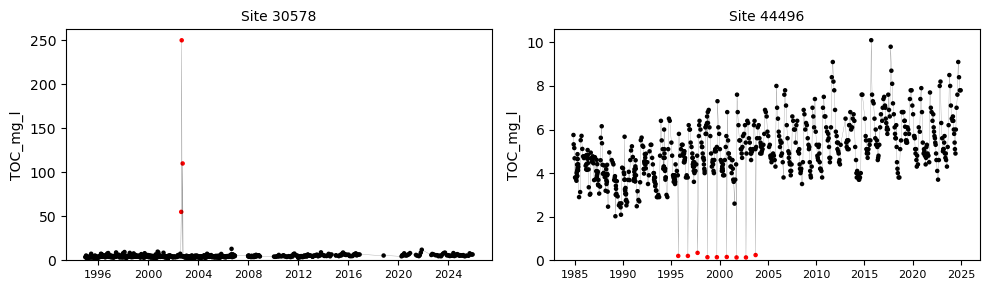

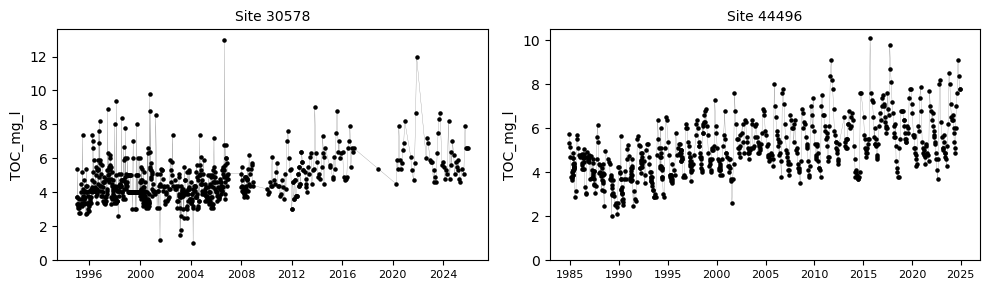

In [48]:
# Quick check for two sites that had some outliers: Looks good (enough).
# (Out of curiosity: the low points in 44496 are all NIVA data)
plot_sites(clean2_df, [30578, 44496], 2, plot_id_col="WaterLocationID", colour_col="TOC_outlier_colour")
plot_sites(no_outliers_df, [30578, 44496], 2, plot_id_col="WaterLocationID")

## Manually clean select periods site-by-site

From looking at time series for sites with a decent amount of data (at least 5 years, at least 10 samples on average per year), I have manually picked out sites that need some closer inspection and likely some manual deletion. These are all documented in a dictionary at the moment.

### Plot all sites with a decent amount of data for manual inspection

In [49]:
# # Plot all sites with decent amount of data
# # Pick sites with lots of years and high sampling frequency
# min_yrs = 8
# min_n_samples = 36
# stn_metadata_df_tmp = stn_metadata_df.query('n_years_with_data > @min_yrs and av_sampling_frequency_peryr > @min_freq')
# plot_site_ids = stn_metadata_df_tmp.index
# print(len(stn_metadata_df_tmp))

# plot_sites(no_outliers_df, plot_site_ids, 2, colour_col="TOC_outlier_colour")

In [50]:
# # For DOC, don't use stn_metadata_df, as most of the data are TOC
# chem_col = 'DOC_mg_l'
# min_samples = 15
# plot_site_ids = n_samples_df.loc[n_samples_df[chem_col] >= min_samples].index
# print(len(plot_site_ids))

# # Plot selected sites
# short_name = short_var_name_dict[chem_col]
# plot_sites(clean2_df, plot_site_ids, 2, chem_col=chem_col, colour_col=f"{short_name}_outlier_colour")

### Close check of sites flagged as looking suspicious to identify whether periods should be deleted

#### TOC

In [51]:
# Enningdalselv and Tista
# sites = ['001-30732', '001-38541']
# plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2001-09-01') & (no_outliers_df['Date'] < '2003-09-01')]
# plot_sites(plot_df, sites, 1, sharex=True, gridon=True)
# plot_df.loc[plot_df['WaterLocationCode'].isin(['001-38541'])]

In [52]:
# # # Dodgy 1999 data ANØ-miljøkompetanse in 002. And Dodgy NorAnalyse data for 60967 from 2015? Decide to leave.
# sites = ['002-29657', '002-29658', '002-29659', '002-30583', '002-46599', '002-60967']
# # sites = ['002-60967']
# # plot_sites(plot_df, sites, 1, sharex=True, gridon=True)
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1997-09-01') & (no_outliers_df['Date'] < '2000-09-01')]
# # plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '2015') & (no_outliers_df['Date'] < '2025')]
# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))

# # display_df = plot_df.loc[plot_df['WaterLocationCode'] == sites[2]]
# # with pd.option_context(
# #     "display.max_rows", None,
# # ):
# #     display(display_df)

In [53]:
# # Dodgy 1999 data ANØ-miljøkompetanse in 002
# sites = ['002-51523']
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1980') & (no_outliers_df['Date'] < '2025')]
# plot_sites(plot_df_trunc, sites, 1, sharex=True, gridon=True)
# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))

In [54]:
# sites = ['002-30582']  # Vorma. Changing providers over time. Delete the first two blocks of data (before 1990).
# sites = ['021-83503']
# sites = ['015-38515']  # Numedalslågen (elvetilførselsprogrammet)
# sites = ['015-65432']  # Referanseelver, step changes in NIVA data year on year
# sites = ['030-44501']  # Ambio AS data (low precision)
# sites = ['123-38525']  # Nidelva (Trøndelag), high & low precision, & one NIVA elvetilførsels d.p. from 1/1/1996
# sites = ['155-38539']  # Røssåga (elveovervåkingsprogrammet). Naturtjenester i Nord has high values in 2018 compared to NIVA. Leave in - NIVA may have low bias
# sites = ['310-55921', '310-55929']  # low precision, repeat values. DL probably. But quite low values. Leave. Maybe LabNett & NIVA are the same?
# sites = ['002-29659', '002-29658']  # low precision for ANØ-miljøkompetanse for a few years. Don't know what to do about step-change in Rambøll Norge... Leave for now
# sites = ['020-103207', '020-103209']  # Dams in dyreparken. Delete values > 80? Yes, not capturable with model even if real
# sites = ['022-85053', '022-85054']  # One outlier per site (one > 200, the other > 80). Small streams D/S of the E18 W of Krs. Perhaps road building. Delete outliers.

# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1985') & (no_outliers_df['Date'] < '2026')]
# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))
# plot_df.head(12)

In [55]:
# # Glomma (2 monitoring points next to each other, both with long series)
# st_dt = '1990'
# end_dt = '1991'
# glomma_eo_df = no_outliers_df.loc[no_outliers_df['WaterLocationID'] == 38516, :].set_index('Date').sort_index()  # elveovervåknigsprogrammet - dodgy data early 1990, delete
# glomma2_df = no_outliers_df.loc[no_outliers_df['WaterLocationID'] == 30777, :].set_index('Date').sort_index()  # Dodgy 2003 data, delete
# ax = glomma2_df['TOC_mg_l'].loc[st_dt: end_dt].plot(marker='o', color='r', figsize=(20, 6))
# glomma_eo_df['TOC_mg_l'].loc[st_dt: end_dt].plot(marker='o', ax=ax)
# plt.ylim(ymin=0)
# plt.grid()
# plt.show()

# # glomma2_df['TOC_mg_l'].loc['2002':'2004']
# glomma_eo_df['TOC_mg_l'].loc[st_dt: end_dt].head(10)

In [56]:
# Ellingsrudelva (Oslo kommune): 2/3 of data (a full year) has 1mg/l precision for TOC; next summer has 0.1 mg/l precision. Decide to keep for now.
# sites = ['002-54430']
# plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2001-09-01') & (no_outliers_df['Date'] < '2005-09-01')]
# plot_sites(plot_df, sites, 1, sharex=True, gridon=True)
# plot_df.loc[plot_df['WaterLocationCode'] == sites[0]]

In [57]:
# Grimestadbekken
# sites = ['014-32082']
# plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '1998-09-01') & (no_outliers_df['Date'] < '2010-09-01')]
# plot_sites(plot_df, sites, 1, sharex=True, gridon=True)
# plot_df.loc[plot_df['WaterLocationCode'] == sites[0]]

In [58]:
# # Skienselva, NIVA data, elvetilførselsprogrammet, flat period 1993-1999
# sites = ['016-38513']
# plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '1990-09-01') & (no_outliers_df['Date'] < '2001-09-01')]
# plot_sites(plot_df, sites, 1, sharex=True, gridon=True)
# plot_df.loc[plot_df['WaterLocationCode'] == sites[0]]

In [59]:
# # Figgjo (Rogaland)
# sites = ['028-54640']
# plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '1995-09-01') & (no_outliers_df['Date'] < '2016-09-01')]
# plot_df = plot_df.loc[plot_df['WaterLocationCode'] == sites[0]]

# plot_compare_contractors(plot_df, title="Figgjo (Stavanger)", figsize=(15, 4.5))

In [60]:
# # Ragdebrua (Hardanger Miljøsenter)
# sites = ['048-54439']
# plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '1980-09-01') & (no_outliers_df['Date'] < '2016-09-01')]
# plot_df = plot_df.loc[plot_df['WaterLocationCode'] == sites[0]]

# plot_compare_contractors(plot_df, figsize=(15, 4.5))
# plot_df

In [61]:
# # Sites with dodgy values in 2004:
# sites = ['006-51732', '006-51733', '006-51736', '006-54458', '007-39619', '007-51734', '007-56495']
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1980') & (no_outliers_df['Date'] < '2006')]

# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5)) 

In [62]:
# # & one of these also has dodgy repeat values in 2000
# sites = ['007-39619', ]
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '2020') & (no_outliers_df['Date'] < '2025')]

# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))
# plot_df.head()

In [63]:
# # Dodgy repeat values
# # sites = ['151-38520', '212-38518', '028-54639']
# sites = ['036-38519']  # Suldalslågen, elveovervåkingsprogrammet site. Run of values from 1992 to end 1990
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1980') & (no_outliers_df['Date'] < '2002-08')]
# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))

# plot_df.head()

In [64]:
# Contractor effects
# sites = ['014-83883', '014-83879', '014-83881', '014-85270', '014-85308']  # Eurofins (Moss) data in 2017 and sometimes 2024; often different to VestfoldLab (2018-2022/3)
# sites = ['015-28502']  #'Not provided' contractor and 3 very big outliers during that period -> not trustworthy
# sites = ['012-60543']  # 3 contractors far apart; who knows what is  true. Leave all in.
# sites = ['002-81353', '002-83557', '002-83558', '002-83895', '002-83896']  # Conservative approach, only drop ALcontrol for 83557 and 83558
# sites = ['012-27982', '012-27985', '012-27992', '012-57071']  # Strongly suspect that "Not provided" is Vestfoldlab, and should therefore be reclassified (and mostly deleted)
# sites = ['012-29032']  # Weird year all by itself (no monitoring data for years either side), much higher concs, "Not provided"
sites = []

plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1980') & (no_outliers_df['Date'] < '2025')]

for site in sites:
    plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
    plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))

In [65]:
# For these sites, reclassify "Not provided" as "VestfoldLAB AS":
reclassify_as_vestfold_li = ['012-27982', '012-27985', '012-27992', '012-57071']

#### DOC

Only one site looked a bit strange - 008-96039. But that was filtered out above in the manual site removal stage.

In [66]:
# # Dodgy repeat values
# sites = ['008-96039']  # can't see waterway on Vannmiljø, manually removed now
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1985') & (no_outliers_df['Date'] < '2025')]
# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     plot_compare_contractors(plot_df, chem_col="DOC_mg_l", title=site, figsize=(15, 4.5))

# # plot_df.head()

### Manually remove selected periods

Only for TOC. Nothing identified for DOC.

In [67]:
# Results of visual inspection above for TOC

# Delete between periods (inclusive) {st_dt, end_dt, only_for_contractor}
# TOC:
site_del_dict = {
    '001-30732': [
        {'start': '2002-01-01', 'end': '2003-06-30',
         'reason': 'Enningdalselva'}
    ],
    '001-38541': [
        {'start': '2002-01-01', 'end': '2003-06-30',
         'contractor': 'Fylkesmannen i Østfold - Miljøvernavdelingen',
         'reason': 'Tista. Note: 2 good data points from NIVA in this period'}
    ],
    '002-29657': [
        {'start': '1999-01-01', 'end': '1999-12-31',
         'reason': 'Leira, first year with ANØ-miljøkompetanse as contractor, low precision'}
    ],
    '002-29658': [
        {'start': '1999-01-01', 'end': '1999-12-31',
         'reason': 'First year with ANØ-miljøkompetanse as contractor, low precision'}
    ],
    '002-29659': [
        {'start': '1999-01-01', 'end': '1999-12-31',
         'reason': 'First year with ANØ-miljøkompetanse as contractor, low precision'}
    ],
    '002-30582': [
        {'start': '1980-01-01', 'end': '1989-10-16',
         'reason': 'Vorma. First period biased very high. Then very low precision'}
    ],
    '002-30583': [
        {'start': '1999-01-01', 'end': '1999-12-31',
         'reason': 'Leira, first year with ANØ-miljøkompetanse as contractor, low precision'}
    ],
    '002-30777': [
        {'start': '2002-01-27', 'end': '2003-06-23',
         'reason': 'Glomma just D/S of RID station'}
    ],
    '002-38516': [
        {'start': '1990-01-01', 'end': '1990-03-31',
         'reason': 'Glomma RID station. First 3 months in 1990 have same repeat value (3.27). Better data from 002-30777'}
    ],
    '002-46599': [
        {'start': '1999-01-01', 'end': '1999-12-31',
         'reason': 'Sagelva, first year with ANØ-miljøkompetanse as contractor, low precision'}
    ],
    '002-51523': [
        {'start': '2008-01-01', 'end': '2017-12-31',
         'contractor': 'DAØ',
         'reason': 'Only delete DAØ data: always high at start, then constant over years'}
    ],
    '002-60967': [
        {'start': '1999-01-01', 'end': '1999-12-31',
         'reason': 'First year with ANØ-miljøkompetanse as contractor, low precision'}
    ],
    '006-51732': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'}
    ],
    '006-51733': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'}
    ],
    '006-51736': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'}
    ],
    '006-54458': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'}
    ],
    '007-39619': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'},
        {'start': '2020-05-01', 'end': '2020-12-31',
         'reason': 'Mærradalsbekken, repeat values over time'}
    ],
    '007-51734': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'}
    ],
    '007-56495': [
        {'start': '2000-01-01', 'end': '2004-12-31',
         'reason': 'Oslo kommune VAV data with very low precision in 2003'}
    ],
    '002-83557': [
        {'start': '2015-01-01', 'end': '2017-12-31',
         'contractor': 'ALcontrol',
         'reason': 'Four flat low samples, very different to SGSAnalytics from 2018'}
    ],
    '002-83558': [
        {'start': '2015-01-01', 'end': '2017-12-31',
         'contractor': 'ALcontrol',
         'reason': 'Four flat low samples, very different to SGSAnalytics from 2018'}
    ],
    # Vassom 003-013
    '012-29032': [
        {'start': '1996-01-01', 'end': '1996-12-31',
         'reason': 'No data for a few years before/after, and values in 1996 much higher than other years, "Not provided" contractor'}
    ],
    '013-58930': [
        {'start': '2014-01-01', 'end': '2016-12-31',
         'contractor': 'Not provided',
         'reason': 'Step change for this contractor/period compared to surrounding data'}
    ],
    # 014
    '014-32081': [
        {'start': '1980-01-01', 'end': '1993-12-31',
         'reason': 'High baseline and high peaks compared to rest of record'}
    ],
    '014-61241': [
        {'start': '2013-01-01', 'end': '2013-12-31',
         'contractor': 'Eurofins (Moss)',
         'reason': 'Step change for this contractor/period compared to surrounding data'}
    ],
    '014-83879': [
        {'start': '2017-01-01', 'end': '2024-12-31',
         'contractor': 'Eurofins (Moss)',
         'reason': 'Step change for this contractor/period compared to in-between VestfoldLAB data'}
    ],
    '014-83881': [
        {'start': '2017-01-01', 'end': '2024-12-31',
         'contractor': 'Eurofins (Moss)',
         'reason': 'Step change for this contractor/period compared to in-between VestfoldLAB data'}
    ],
    '014-83883': [
        {'start': '2017-01-01', 'end': '2024-12-31',
         'contractor': 'Eurofins (Moss)',
         'reason': 'Step change for this contractor/period compared to in-between VestfoldLAB data'}
    ],
    '014-85270': [
        {'start': '2017-01-01', 'end': '2024-12-31',
         'contractor': 'Eurofins (Moss)',
         'reason': 'Step change for this contractor/period compared to in-between VestfoldLAB data'}
    ],
    '014-85308': [
        {'start': '2017-01-01', 'end': '2024-12-31',
         'contractor': 'Eurofins (Moss)',
         'reason': 'Step change for this contractor/period compared to in-between VestfoldLAB data'}
    ],
    # Over 015
    '015-28502': [
        {'start': '2009-01-01', 'end': '2010-12-31',
         'contractor': 'Not provided',
         'reason': '3 very high values in this period with a different contractor and a bit of a step change'}
    ],
    '015-38515': [
        {'start': '1980-01-01', 'end': '1998-12-31',
         'reason': 'Numedalslågen, NIVA data, dodgy flat period'}
    ],
    '016-38513': [
        {'start': '1995-12-01', 'end': '1998-04-30',
         'reason': 'Skienselva, flat period, possible fill of missing data'}
    ],
    '028-54639': [
        {'start': '1992-01-01', 'end': '1998-12-31',
         'reason': 'Same value across multiple years (1992–1999), NIVA data'}
    ],
    '030-44501': [
        {'start': '2000-01-01', 'end': '2003-12-31',
         'contractor': 'Ambio AS',
         'reason': 'Slightly higher than NIVA but low precision (1 mg/l)'}
    ],
    '036-38519': [
        {'start': '1992-01-01', 'end': '1998-12-31',
         'reason': 'Elveovervåkingsprogrammet site. Run of constant values'}
    ],
    '048-54439': [
        {'start': '2000-01-01', 'end': '2007-12-31',
         'reason': 'Ragdebrua, change in LOD (Hardanger Miljøsenter)'}
    ],
    '123-38525': [
        {'start': '1980-01-01', 'end': '1996-01-01',
         'reason': 'Nidelva, low precision high data and 1 Jan 1996 issue'}
    ],
    '151-38520': [
        {'start': '1992-01-01', 'end': '1998-12-31',
         'reason': 'Same value across multiple years (1992–1999), NIVA data'}
    ],
    '212-38518': [
        {'start': '1992-01-01', 'end': '1998-12-31',
         'reason': 'Same value across multiple years (1992–1999), NIVA data'}
    ]
}


# Manually list outliers that slipped through automatic outlier detection. Format: for site id, delete values greater than gt_value. Specified by dict: {site_id, gt_value}
# TOC:
del_outliers_dict = {
    '020-103207': 80,
    '020-103209': 80,
    '022-85053': 100,  # Suspect road building effect if not contamination
    '022-85054': 80,   # Suspect road building effect if not contamination
}

# [date_before, DL_subbed], delete conc values if they are equal to DL_subbed, before end_dt.
# TOC:
del_bad_DL_values_dict = {
    '036-38519': ['2000-08-01', 1.0],  # A year of too-high values because 1mg/l seems to have been subbed in for DL. 0.5 mg/L subbed in after, then better.
}

In [68]:
# Do some assertions to check dict is ok
# Basic checks
for site_id, periods in site_del_dict.items():
    assert isinstance(periods, list), f"{site_id} must map to a list"
    for p in periods:
        assert 'start' in p and 'end' in p, f"{site_id} entry missing start/end"
# Assert that start date < end date
for site, periods in site_del_dict.items():
    for p in periods:
        assert pd.to_datetime(p['start']) <= pd.to_datetime(p['end']), \
            f"Invalid date range for {site}: {p}"


# Apply

# Log number of samples/sites at the start
print("Rows before cleaning:", len(no_outliers_df))
print("Sites before cleaning:", len(no_outliers_df['WaterLocationID'].unique()))

print("Rows before cleaning, after NaN dropping:", len(no_outliers_df.dropna(subset=var_li, how='all')))
print("Sites before cleaning, after NaN dropping:", len(no_outliers_df.dropna(subset=var_li, how='all')['WaterLocationID'].unique()))


# Initialise counters for removed samples
total1_removed = 0
total2_removed = 0
total3_removed = 0


for site_id, periods in site_del_dict.items():

    # If site ID is wrong, add warning (otherwise will silently fail)
    # if site_id not in no_outliers_df['WaterLocationCode'].values:
    #     print(f"WARNING: {site_id} not found in dataset")

    site_mask = no_outliers_df['WaterLocationCode'] == site_id

    for period in periods:
        st_date = pd.to_datetime(period['start'])
        end_date = pd.to_datetime(period['end'])
        contractor = period.get('contractor', None)

        mask = (
            site_mask &
            (no_outliers_df['Date'] >= st_date) &
            (no_outliers_df['Date'] <= end_date)
        )

        if contractor is not None:
            mask &= (no_outliers_df['Contractor_simple'] == contractor)

        no_outliers_df.loc[mask, 'TOC_mg_l'] = np.nan

        # Logging
        n = mask.sum()
        # print(f"{site_id}: removed {n} rows from {st_date.date()} to {end_date.date()}"
        #       + (f" (contractor={contractor})" if contractor else ""))

        if n == 0:
            print(f"WARNING: {site_id} matched 0 rows "
                  f"({st_date.date()} → {end_date.date()})"
                  + (f", contractor={contractor}" if contractor else ""))

        total1_removed += n

print ("")
print(f"Total samples removed by manual removal of dodgy periods: {total1_removed}")


# Delete manually-identified outliers that slipped through the outlier detection
for site_id, threshold in del_outliers_dict.items():
    mask = (
        (no_outliers_df['WaterLocationCode'] == site_id) &
        (no_outliers_df['TOC_mg_l'] > threshold)
    )
    no_outliers_df.loc[mask, 'TOC_mg_l'] = np.nan

    # Logging
    n = mask.sum()
    total2_removed += n

print(f"Total samples removed through manual outlier detection: {total2_removed}")


# Dodgy DL substitutions. Delete censored values altogether. Note: will bias-high if taking summary
# stats,  but that's not our main concern/purpose here
for site_id, vals in del_bad_DL_values_dict.items():
    end_dt, dl_value = vals
    end_dt = pd.to_datetime(end_dt)
    mask = (
        (no_outliers_df['WaterLocationCode'] == site_id) &
        (no_outliers_df['TOC_mg_l'] == dl_value) &
        (no_outliers_df['Date'] <= end_dt)
    )
    no_outliers_df.loc[mask, 'TOC_mg_l'] = np.nan
    # Logging
    n = mask.sum()
    total3_removed += n

print(f"Total samples removed due to dodgy DL value substitutions: {total3_removed}")

total_removed = total1_removed + total2_removed + total3_removed

print("Total number of samples removed by manual cleaning:", total_removed)
print("")


# -----------------------------
# Tidy no_outliers_df

# Drop unwanted columns
final_df_keep_cols = [
    "WaterLocationCode",
    "lon",
    "lat",
    "WaterLocationID",
    "Name",
    "Contractor_simple",
    "ActivityName",
    "Date"
] + var_li

no_outliers_df = no_outliers_df[final_df_keep_cols]

# Drop rows where all data cols are NaNs
print("Total rows before dropping NaNs:", len(no_outliers_df))
print("Sites before dropping NaNs:", len(no_outliers_df['WaterLocationID'].unique()))

no_outliers_df = no_outliers_df.dropna(subset=var_li, how='all')

print("Total rows after cleaning and dropping NaNs:", len(no_outliers_df))
print("Sites after cleaning and dropping NaNs:", len(no_outliers_df['WaterLocationID'].unique()))

no_outliers_df.head()

Rows before cleaning: 181039
Sites before cleaning: 10846
Rows before cleaning, after NaN dropping: 181039
Sites before cleaning, after NaN dropping: 10846

Total samples removed by manual removal of dodgy periods: 1083
Total samples removed through manual outlier detection: 4
Total samples removed due to dodgy DL value substitutions: 7
Total number of samples removed by manual cleaning: 1094

Total rows before dropping NaNs: 181039
Sites before dropping NaNs: 10846
Total rows after cleaning and dropping NaNs: 179945
Sites after cleaning and dropping NaNs: 10846


,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor_simple,ActivityName,Date,DOC_mg_l,TOC_mg_l
0,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2011-09-15,NaN,10.61
1,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2012-10-09,NaN,9.96
2,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2013-08-27,NaN,9.39
3,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2014-08-19,NaN,7.46
4,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2015-08-28,NaN,8.40


# Add flags for VestfoldLAB TOC data for easy removal later

On basis of time series plots comparing contractors (see below), and DOC/TOC ratio (also below), decide that all the VestfoldLAB TOC data is suspect. The DOC data look better. Dropping the data would be 10% of all samples and 25% of sites would be affected (not necessarily removed - depends if other contractors also have data from those sites). But overall it could result in loosing a lot of coverage to just drop all VestfoldLAB dta. So what is the best approach?

In ML-based environmental modeling:

* Losing temporal consistency is very harmful, which means that it's very likely we want to remove dodgy lab data when it is just a small part of a longer time series
* Losing some absolute accuracy is often tolerable, meaning that some spatial bias might be ok. But only if the lab doesn't strongly cluster in certain regions or time periods. Which it does...
* Losing spatial coverage can can be harmful, and this lab was the only source of data for quite a lot of nice-looking catchments.

So it's very likely I will delete the TOC data altogether. But for now, decide to add two quality flags:
1) flag_lab_within_site: flag VestfoldLAB data in sites which have a decent amount of data from other labs (i.e. the limed stations) -> ensure temporal consistency, so the ML model doesn't mistake lab changes as environmental effects.
2) flag_lab_full_site: For sites where we only have data from VestfoldLAB. This has a couple of benefits: we get catchment characteristics for all the catchments, so if I change my mind later I don't have to rerun everything.
  
And then in the ML, we have the options to do a sensitivity analysis with and without the VestfoldLAB sites to quantify the impact on general performance, temporal behaviour and spatial patterns.

In [69]:
# Expore number of data points with VestfoldLAB as named contractor
contractor = 'VestfoldLAB AS'
chem_col = 'TOC_mg_l'

vestfoldlab_rows = no_outliers_df.loc[no_outliers_df['Contractor_simple'] == contractor, :].dropna(subset=[chem_col])
all_rows = no_outliers_df[['WaterLocationCode', chem_col]].dropna(subset=[chem_col])  # chem_col samples only
tot_rows = len(all_rows)

n_sites_with_vestfold = vestfoldlab_rows['WaterLocationCode'].nunique()
n_sites_tot = all_rows['WaterLocationCode'].nunique()

print("Rows (individual samples) with VestfoldLab TOC data:", len(vestfoldlab_rows))
print("Original number of TOC samples:", tot_rows)
print("Proportion of TOC samples affected (%):", (round(100 * (len(vestfoldlab_rows) / tot_rows))))
print("")
print("Total sites with data for TOC:", n_sites_tot)
print("Sites with vestfoldlab data for TOC:", n_sites_with_vestfold)
print("Proportion of sites affected (roughly) (%):", (round(100 * (n_sites_with_vestfold / n_sites_tot))))

vestfoldlab_rows[['ActivityName', 'TOC_mg_l']].groupby('ActivityName').describe()

Rows (individual samples) with VestfoldLab TOC data: 18503
Original number of TOC samples: 177839
Proportion of TOC samples affected (%): 10

Total sites with data for TOC: 10753
Sites with vestfoldlab data for TOC: 2917
Proportion of sites affected (roughly) (%): 27


TOC_mg_l                             \
                                             count      mean        std   min   
ActivityName                                                                    
Annet                                       3976.0  4.092511   3.111398  0.10   
Effekter av vassdragsinngrep                  42.0  4.130238   5.168838  0.50   
Kartlegging av kalksjøer                      30.0  7.000000   2.747789  3.30   
Lokal overvåking av kalka vassdrag          3084.0  9.787835   5.171162  0.30   
Overvåking av drikkevann                     739.0  8.469689   5.232450  1.20   
Overvåking av trua arter                       3.0  6.366667   1.078579  5.60   
Problemkartlegging                           272.0  6.296544   3.708996  0.50   
Tiltaksorientert overvåking                 6196.0  7.529937  14.368606  0.40   
Tiltaksovervåking i kalkede laksevassdrag   4161.0  3.690654   2.766456  0.16   

                                                                      
                                            25%   50%     75%    max  
ActivityName                                                          
Annet                                      2.00  3.50   5.225   43.3  
Effekter av vassdragsinngrep               1.35  2.80   5.350   24.9  
Kartlegging av kalksjøer                   5.40  6.25   8.425   16.3  
Lokal overvåking av kalka vassdrag         6.30  8.90  12.500   38.3  
Overvåking av drikkevann                   5.60  7.10   9.500   39.3  
Overvåking av trua arter                   5.75  5.90   6.750    7.6  
Problemkartlegging                         3.60  5.75   8.700   19.6  
Tiltaksorientert overvåking                4.50  6.60   8.900  734.0  
Tiltaksovervåking i kalkede laksevassdrag  1.70  2.90   5.100   27.7

In [70]:
# # Exploring some of the data that isn't from the limed programmes
# yr_df = vestfoldlab_rows.loc[vestfoldlab_rows['Year'] == 2020]
# len(yr_df['Name'].unique())
# yr_df['ActivityName'].unique()
# not_limed_yr_df = yr_df.loc[yr_df['ActivityName'].isin(['Tiltaksorientert overvåking', 'Overvåking av drikkevan', 'Annet'])]
# # not_limed_yr_df['Name'].unique()

**Final strategy used for now:**

To account for potential bias in measurements from VestfoldLAB AS, we implement a two-tier flagging strategy to distinguish between within-site inconsistencies and systematic site-level bias, while preserving as much useful data as possible. For each site, we calculate the proportion of samples analysed by VestfoldLAB and the total number of observations. Based on this, samples were classified as follows:

* **Within-site flag (flag_lab_within_site)**:

    Applied to VestfoldLAB samples at sites where:

    - Multiple labs contribute meaningfully (VestfoldLAB < 70% of samples),
    - The site has sufficient data (≥ 20 samples), and
    - Observations occur before 2020 (period with known inconsistencies).
  
  These samples are assumed to introduce temporal inconsistencies and are removed when the data are compiled for ML (but not in the csv saved here - just flagged there).


* **Full-site flag (flag_lab_full_site)**:

    Applied to VestfoldLAB samples at sites where the lab dominates (≥ 70% of samples).
    These sites are flagged as having potential systematic bias, but we likely want to keep them anyway to preserve spatial coverage. But flag them to test sensitivity of the ML to them.


This approach prioritises preserving temporal consistency for model training while retaining spatial information where bias is likely more uniform. Sensitivity analyses can be performed by further excluding full-site flagged data. Note that Sites with small sample sizes (< 20 observations) are excluded from within-site flagging, as limited data prevents robust detection of inter-lab inconsistencies.

**Result of targetted removing of within-site data:**

If site has 80% vestfoldlab data, flag as whole-site:

* Sites with suspect lab but < 20 samples (not flagged within-site): 2511
* Number of sites affected by within-site lab flags: 251
* Number of sites affected by full-site lab flags: 1232
* Rows flagged (within-site): 4918
* Rows flagged (full-site): 6659
* Original number of TOC samples 178043
* Final number of TOC samples after removing within-site flagged samples: 173125

If site has 70% vestfoldlab data, flag as whole-site:

* Sites with suspect lab but < 20 samples (not flagged within-site): 2511
* Number of sites affected by within-site lab flags: 203
* Number of sites affected by full-site lab flags: 1444
* Rows flagged (within-site): 3951
* Rows flagged (full-site): 9033
* Original number of TOC samples 178043
* Final number of TOC samples after removing within-site flagged samples: 174092

In [71]:
flag_lab_df = no_outliers_df.copy()

contractor = 'VestfoldLAB AS'
chem_col = 'TOC_mg_l'
site_col = 'WaterLocationCode'
lab_col = 'Contractor_simple'

# Criteria for flagging vestfold lab samples
dominance_threshold = 0.7  # If > this proportion are vestfoldlab samples, give sample whole site dodgy lab flag
min_samples = 20  # For a within-site flag, only apply if the site has > min_samples and < dominance_threshold are Vestfoldlab samples
end_date_bad_data = '2019-12-31'  # For within-site flag, only apply before this end_date (incl.)

# Just in case
flag_lab_df['Date'] = pd.to_datetime(flag_lab_df['Date'], errors='coerce')
end_date_bad_data = pd.to_datetime(end_date_bad_data)

# --- 1. Keep only rows with valid chemistry ---
df_valid = flag_lab_df.loc[flag_lab_df[chem_col].notna()].copy()

# --- 2. Total samples per site ---
total_counts = (
    df_valid
    .groupby(site_col)
    .size()
    .rename('n_total')
    .reset_index()
)

# --- 3. Vestfold samples per site ---
vestfold_counts = (
    df_valid[df_valid[lab_col] == contractor]
    .groupby(site_col)
    .size()
    .rename('n_vestfold')
    .reset_index()
)

# --- 4. Merge counts ---
site_counts = total_counts.merge(vestfold_counts, on=site_col, how='left')

# Fill NaN → 0 (sites with no Vestfold samples)
site_counts['n_vestfold'] = site_counts['n_vestfold'].fillna(0)

# --- 5. Compute fraction ---
site_counts['suspect_frac'] = (
    site_counts['n_vestfold'] / site_counts['n_total']
)

# --- 6. Merge back into main df ---
flag_lab_df = flag_lab_df.merge(
    site_counts[[site_col, 'n_total', 'suspect_frac']],
    on=site_col,
    how='left'
)

# Fill NaN (sites without suspect lab or data)
flag_lab_df['suspect_frac'] = flag_lab_df['suspect_frac'].fillna(0)
flag_lab_df['n_total'] = flag_lab_df['n_total'].fillna(0)


# --- Create flags ---
flag_lab_df['flag_lab_within_site'] = 0
flag_lab_df['flag_lab_full_site'] = 0

is_suspect_lab = flag_lab_df[lab_col] == contractor
has_value = flag_lab_df[chem_col].notna()

# Case A: meaningful multi-lab site
mask_within = (
    is_suspect_lab &
    has_value &
    (flag_lab_df['suspect_frac'] < dominance_threshold) &
    (flag_lab_df['n_total'] >= min_samples) &
    (flag_lab_df['Date'] <= end_date_bad_data)
)

# Case B: dominated by suspect lab (effectively full-site)
# (don't care about number of samples in this case)
mask_full = (
    is_suspect_lab &
    has_value &
    (flag_lab_df['suspect_frac'] >= dominance_threshold) &
    (flag_lab_df['Date'] <= end_date_bad_data)
)

# Assign
flag_lab_df.loc[mask_within, 'flag_lab_within_site'] = 1
flag_lab_df.loc[mask_full, 'flag_lab_full_site'] = 1

# --- Diagnostics ---
flagged_within_site_ids = flag_lab_df.loc[flag_lab_df['flag_lab_within_site'] == 1]['WaterLocationCode'].unique()
flagged_full_site_ids = flag_lab_df.loc[flag_lab_df['flag_lab_full_site'] == 1]['WaterLocationCode'].unique()


n_small_sites = flag_lab_df.loc[
    (flag_lab_df['n_total'] < min_samples) &
    (flag_lab_df['suspect_frac'] > 0),
    site_col
].nunique()

over_min_n_df = flag_lab_df.loc[flag_lab_df['n_total'] >= min_samples]
print("Number of samples in sites with n>min_samples:", len(over_min_n_df))
print("Number of sites with n>min_samples:", len(over_min_n_df['WaterLocationCode'].unique()))

under_frac_df = flag_lab_df.loc[flag_lab_df['suspect_frac'] < dominance_threshold]
print("Number of samples in sites with % vestfoldlab < min_fraction (ie multilab):", len(under_frac_df))
print("Number of sites with % vestfoldlab < min_fraction (ie multilab):", len(under_frac_df['WaterLocationCode'].unique()))

print(f"Sites with suspect lab but < {min_samples} samples (not flagged within-site):", n_small_sites)

print("")
print("Number of sites affected by within-site lab flags:", len(flagged_within_site_ids))
print("Number of sites affected by full-site lab flags:", len(flagged_full_site_ids))
print("")
print("Rows flagged (within-site):", flag_lab_df['flag_lab_within_site'].sum())
print("Rows flagged (full-site):", flag_lab_df['flag_lab_full_site'].sum())

flag_lab_df.head()

Number of samples in sites with n>min_samples: 133131
Number of sites with n>min_samples: 1484
Number of samples in sites with % vestfoldlab < min_fraction (ie multilab): 169911
Number of sites with % vestfoldlab < min_fraction (ie multilab): 9404
Sites with suspect lab but < 20 samples (not flagged within-site): 2510

Number of sites affected by within-site lab flags: 203
Number of sites affected by full-site lab flags: 713

Rows flagged (within-site): 3956
Rows flagged (full-site): 4264


,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor_simple,ActivityName,Date,DOC_mg_l,TOC_mg_l,n_total,suspect_frac,flag_lab_within_site,flag_lab_full_site
0,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2011-09-15,NaN,10.61,14.0,0.0,0,0
1,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2012-10-09,NaN,9.96,14.0,0.0,0,0
2,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2013-08-27,NaN,9.39,14.0,0.0,0,0
3,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2014-08-19,NaN,7.46,14.0,0.0,0,0
4,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2015-08-28,NaN,8.40,14.0,0.0,0,0


In [72]:
# # QC plot - flagged sites
# # sites = flagged_full_site_ids[1500:2000]  # i.e. not deleting yet, do sensitivity analysis on effect of data
# sites = flagged_within_site_ids[:70]  # i.e. likely delete vestfoldlab data
# plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1980') & (no_outliers_df['Date'] < '2026')]
# for site in sites:
#     plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
#     if len(plot_df) < 6:
#         continue
#     plot_compare_contractors(plot_df, title=site, figsize=(8, 2))

In [73]:
# # --- Remove within-site only samples? ---
# rows_to_del = flag_lab_df.loc[mask_within, :]
# flag_lab_df.loc[mask_within, chem_col] = np.nan

# # drop any rows which are now all NaNs for data
# flag_lab_df = flag_lab_df.dropna(subset=var_li, how='all')

# print("Original number of TOC samples", len(no_outliers_df[chem_col].dropna()))
# print("Final number of TOC samples after removing within-site flagged samples:", len(flag_lab_df[chem_col].dropna()))
# print("Number of rows after removing within-site flagged samples:", len(flag_lab_df))

# print("")
# print("Original number of sites:", len(no_outliers_df['WaterLocationCode'].unique()))
# print("Final number of sites:", len(flag_lab_df['WaterLocationCode'].unique()))

# Add QUANTOM sensor data & save

In [74]:
# reformat vm data

# Rename contractor
flag_lab_df = flag_lab_df.rename({'Contractor_simple': 'Contractor'}, axis=1)

# Drop helper columns
final_vm_df = flag_lab_df.drop(['suspect_frac', 'n_total'], axis=1)


if add_quantom is True:
    quant_fpath = r"/home/jovyan/shared/common/norsink/waterchem/quantom/quantom_sensor_data_reformatted_for_vm.csv"
    quant_df = pd.read_csv(quant_fpath)
    quant_df['Date'] = pd.to_datetime(quant_df['Date'])

    vm_quant_df = pd.concat([final_vm_df, quant_df], ignore_index=True, sort=False)
    vm_quant_df['Date'] = pd.to_datetime(vm_quant_df['Date'])  # needed, mixed format datetimes

    print("Vannmiljø samples:", len(final_vm_df))
    print("Quantom samples:", len(quant_df))
    print("Samples, combined dataset:", len(vm_quant_df))

    print("Vannmiljø sites:", len(final_vm_df['WaterLocationCode'].unique()))
    print("Quantom sites:", len(quant_df['WaterLocationCode'].unique()))
    print("Sites, combined dataset:", len(vm_quant_df['WaterLocationCode'].unique()))

    display(vm_quant_df)

Vannmiljø samples: 179945
Quantom samples: 2068
Samples, combined dataset: 182013
Vannmiljø sites: 10846
Quantom sites: 11
Sites, combined dataset: 10857


,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor,ActivityName,Date,DOC_mg_l,TOC_mg_l,flag_lab_within_site,flag_lab_full_site
0,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2011-09-15,NaN,10.61,0,0
1,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2012-10-09,NaN,9.96,0,0
2,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2013-08-27,NaN,9.39,0,0
3,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2014-08-19,NaN,7.46,0,0
4,001-119928,11.653745,59.47652,119928,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2015-08-28,NaN,8.40,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
182008,234-M4,27.000550,69.78289,-4,Utsjoki (Patoniva),JHI,Forskning,2023-10-12,3.348104,NaN,0,0
182009,234-M4,27.000550,69.78289,-4,Utsjoki (Patoniva),JHI,Forskning,2023-10-13,3.316000,NaN,0,0
182010,234-M4,27.000550,69.78289,-4,Utsjoki (Patoniva),JHI,Forskning,2023-10-14,3.316000,NaN,0,0
182011,234-M4,27.000550,69.78289,-4,Utsjoki (Patoniva),JHI,Forskning,2023-10-15,3.292271,NaN,0,0


In [75]:
# Save vm-only and combined dataset
out_fpath = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/clean/vannmiljø_toc_doc_cleaned_before_delineation.csv"
final_vm_df.to_csv(out_fpath, index=False)

if add_quantom is True:
    vm_quant_fpath = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/clean/vannmiljø_quantom_toc_doc_cleaned_before_delineation.csv"
    vm_quant_df.to_csv(vm_quant_fpath)

In [76]:
# Rename vm_quant_df for use in processing below
if add_quantom is True:
    final_df = vm_quant_df
else:
    final_df = final_vm_df

# Remake stn_df, recalculate metadata & save

## Make station df and some QC on it

In [77]:
# Recalculate stn_df from scratch, in case have added non-VM data
stn_df = final_df[site_df_cols].drop_duplicates().reset_index(drop=True)

stn_df

,WaterLocationCode,lon,lat,WaterLocationID,Name
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE"
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN
...,...,...,...,...,...
10852,234-3c,24.010930,69.328190,-6,Skierrejohka
10853,234-9b,26.423990,69.967740,-7,Darjohka
10854,234-M3,25.144760,69.395210,-3,Karasjohka
10855,234-15,24.196780,69.339190,-11,Liebetjohka


In [78]:
# # Duplicate lat/lon points with different site IDs?
# dp = 5
# stn_df['lat_rounded'] = stn_df['lat'].round(decimals=dp)
# stn_df['lon_rounded'] = stn_df['lon'].round(decimals=dp)

# duplicate_sites_df = stn_df[stn_df.duplicated(['lat_rounded', 'lon_rounded'], keep=False)]
# print("Number of duplicate sites: %s" % len(duplicate_sites_df))
# display(duplicate_sites_df.sort_values('lat'))

# # Drop rounded cols again
# stn_df = stn_df.drop(['lat_rounded', 'lon_rounded'], axis=1)

Not many duplicate sites. From their site names, it looks like they are actually different sites on the whole. Won't worry about them, as they are only a handful and their names make them sound small.

In [79]:
# # Check lat/lon are sensible for mainland Norway - all good (given generous box)
# # Generous box
# lat_min, lat_max = 57.5, 71.5
# lon_min, lon_max = 4.0, 31.5

# # boolean mask: True if inside Norway bounds
# inside_bounds = (
#     stn_df["lat"].between(lat_min, lat_max) &
#     stn_df["lon"].between(lon_min, lon_max)
# )

# # rows outside bounds
# outside_df = stn_df[~inside_bounds]

# print(f"{len(outside_df)} rows outside bounds")

## Recalculate water chem metadata

In [80]:
# Calculate metadata

flag_cols = ['flag_lab_within_site', 'flag_lab_full_site']
final_df_meta_cols = meta_cols_no_depth + flag_cols

start_date_df, end_date_df = start_end_dates_df(final_df, final_df_meta_cols)
year_df, start_year_s, end_year_s = make_n_years_df(start_date_df, end_date_df)
n_years_df = calculate_record_length(end_date_df, start_date_df)
mean_n_years_s, max_n_years_s = calc_years_with_data(n_years_df)
n_samples_df, n_samples_s = calc_number_of_samples_per_site(final_df)
av_samples_pr_yr_df = calc_av_samps_per_yr(n_samples_df, n_years_df)
max_samp_pr_yr_s = max_samps_per_yr(av_samples_pr_yr_df)

final_stn_metadata_df = make_station_metadata_df(stn_df, start_year_s, end_year_s, max_n_years_s, n_samples_s, max_samp_pr_yr_s)
final_stn_metadata_df.head()

,lon,lat,WaterLocationID,Name,start_year,end_year,n_years_with_data,n_samples,av_sampling_frequency_peryr
WaterLocationCode,,,,,,,,,
001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00
001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00
001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00
001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17
001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00


In [81]:
# Save metadata df
stn_fpath = "/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/outlet_locations_vm-rivs-quant-oc_b4-delineation.csv"
final_stn_metadata_df.to_csv(stn_fpath, index=True)

Raw metadata:

Total sites: 11028
Number of sites with only 1 sample: 2218
Number of sites with < 10 samples: 9485
Number of sites with >= 10 samples: 1543


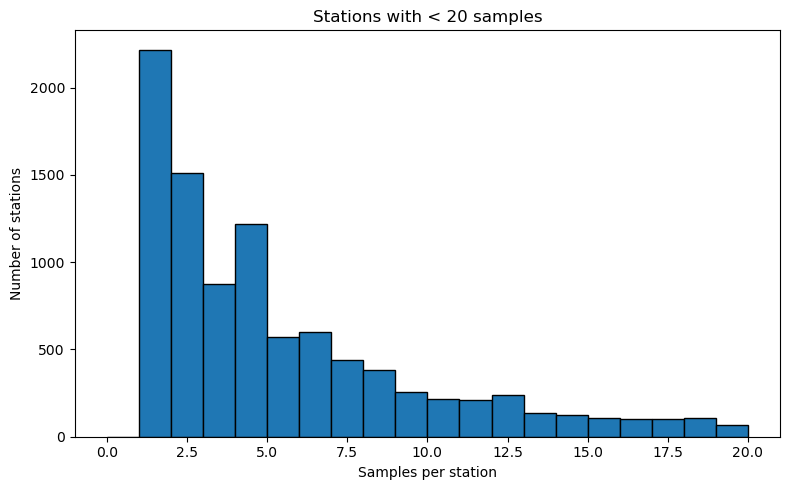

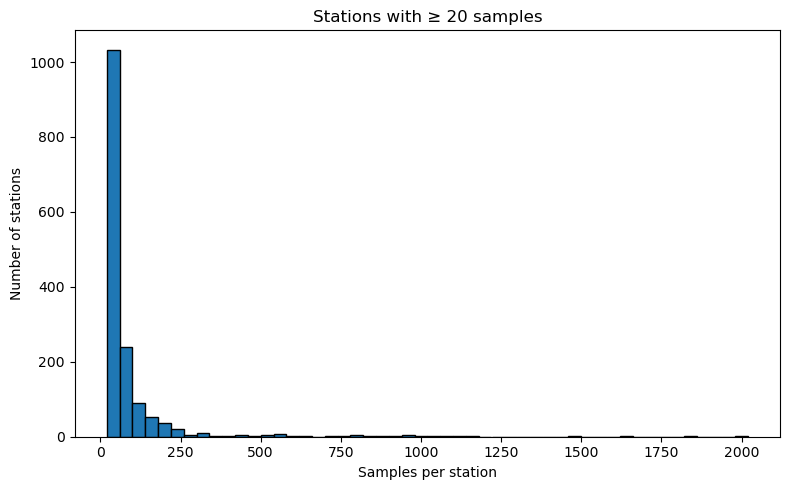


Metadata after cleaning:
Total sites: 10857
Number of sites with only 1 sample: 2193
Number of sites with < 10 samples: 9355
Number of sites with >= 10 samples: 1502


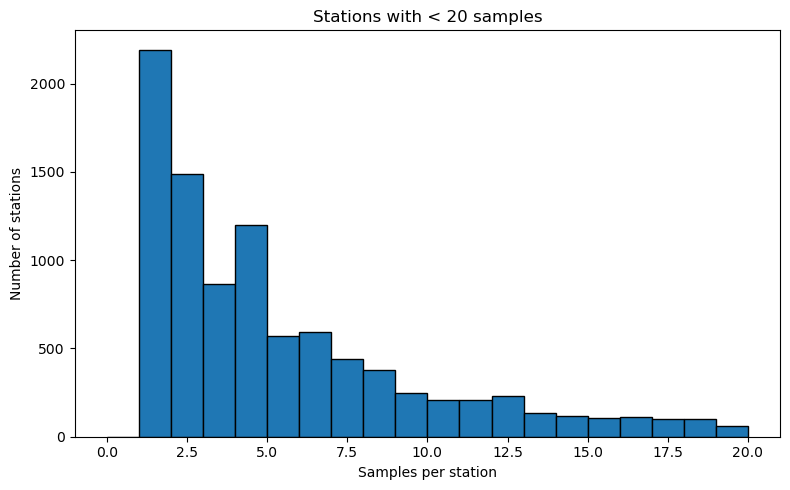

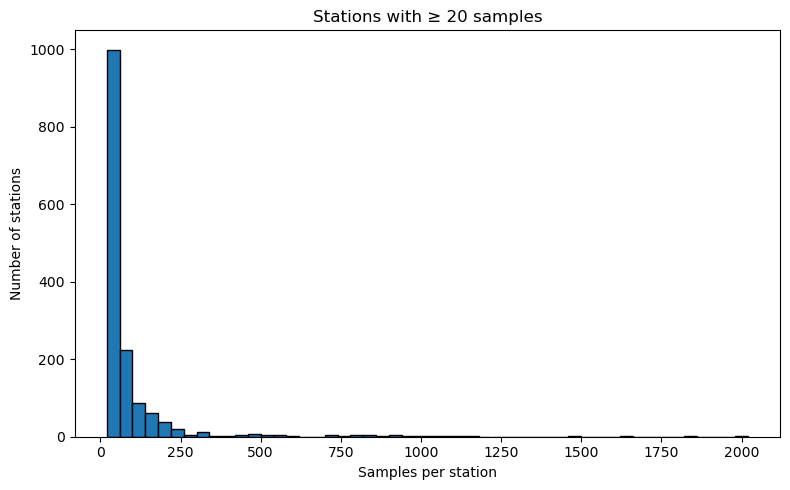

In [82]:
def summarise_metadata(stn_metadata_df, thresh):
    # Number of sites with only one sample:
    print(f"Total sites: {len(stn_metadata_df)}")
    sites_with_1_sample = len(stn_metadata_df.loc[stn_metadata_df['n_samples'] == 1])
    print(f"Number of sites with only 1 sample: {sites_with_1_sample}")

    # Split the dataframe
    df_lt = stn_metadata_df[stn_metadata_df['n_samples'] < thresh]
    df_ge = stn_metadata_df[stn_metadata_df['n_samples'] >= thresh]

    print(f"Number of sites with < 10 samples: {len(df_lt)}")
    print(f"Number of sites with >= 10 samples: {len(df_ge)}")

    # --- Histogram 1: n_samples < thresh ---
    plt.figure(figsize=(8,5))
    df_lt['n_samples'].plot.hist(
        bins=range(0, thresh + 1),
        edgecolor='black'
    )
    plt.title(f'Stations with < {thresh} samples')
    plt.xlabel('Samples per station')
    plt.ylabel('Number of stations')
    plt.tight_layout()
    plt.show()

    # --- Histogram 2: n_samples >= 10 ---
    plt.figure(figsize=(8,5))
    df_ge['n_samples'].plot.hist(
        bins=50,
        edgecolor='black'
    )
    plt.title(f'Stations with ≥ {thresh} samples')
    plt.xlabel('Samples per station')
    plt.ylabel('Number of stations')
    plt.tight_layout()
    plt.show()


print("Raw metadata:")
print("")
summarise_metadata(raw_stn_metadata_df, 20)

print("")
print("Metadata after cleaning:")
summarise_metadata(final_stn_metadata_df, 20)


In [83]:
# Which sites have tonnes of data points?
final_stn_metadata_df.loc[final_stn_metadata_df['n_samples'] > 600]

,lon,lat,WaterLocationID,Name,start_year,end_year,n_years_with_data,n_samples,av_sampling_frequency_peryr
WaterLocationCode,,,,,,,,,
001-38541,11.444334,59.127828,38541,"Tista, utløp Femsjøen (FEMU)",1990,2025,35.7,841,23.56
002-29666,11.265028,60.083562,29666,Rømua ved Kauserud (R1),1981,2010,29.3,1023,34.95
002-30575,11.097946,60.022853,30575,Frogner Leira,1983,2025,42.9,1075,25.03
002-30578,11.008502,59.979252,30578,Kjellerholen Nitelva,1995,2025,30.9,725,23.44
002-30583,11.080568,60.133023,30583,Leira ved Kråkfossen,1996,2025,29.8,794,26.67
002-30586,11.057005,59.945528,30586,Rud Nitelva,1981,2020,39.9,823,20.62
002-30714,11.248314,59.523081,30714,"Hera (HER1), Eidsberg kommune St NIVA 3",1997,2025,28.8,786,27.34
002-30751,11.227087,59.438490,30751,Rakkestadelva ved Brekke (RAK 1),1998,2025,27.9,811,29.04
002-46599,11.016949,59.958502,46599,Sagelva ved Skjetten bro (F3),1995,2025,30.9,737,23.82


Most TOC data of all: Birkenes! Followed closely by Storgama. i.e. the Feltfo sites are the longest and highest frequency (as expected).

# Quick QC plots of remaining data and sites

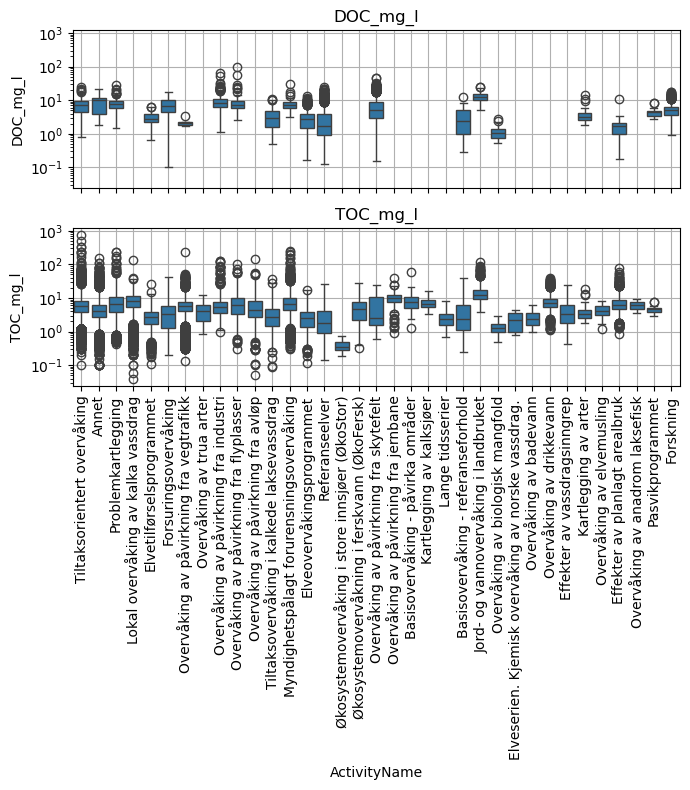

In [84]:
vars_to_plot = ['DOC_mg_l', 'TOC_mg_l']

nvars = len(vars_to_plot)
ncols = 1
nrows = nvars

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(7*ncols, 4*nrows),
    sharey=True,
    sharex=True
)

axes = axes.flatten()

for ax, var in zip(axes, vars_to_plot):
    sns.boxplot(
        data=final_df[[var, "ActivityName"]],
        y=var,
        x="ActivityName",
        ax=ax,
        hue=None,
        showfliers=True
    )
    ax.set_yscale("log")
    ax.set_title(var)
    ax.grid('on')

plt.xticks(rotation=90, ha='center')

# Hide unused axes if any
for ax in axes[nvars:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Plot site locations
## All sites

In [85]:
# All sites
stn_gdf = gpd.GeoDataFrame(stn_df, geometry=gpd.points_from_xy(stn_df.lon, stn_df.lat), crs="EPSG:4326")
stn_gdf = stn_gdf.to_crs("EPSG:25833")

stn_gdf = stn_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()

print(len(stn_df), "River stations in Norway with OC data")
nivapy.spatial.quickmap(
    stn_gdf, kartverket=True, popup='WaterLocationCode', aerial_imagery=False
)

10857 River stations in Norway with OC data


**Comments:**

- Still quite a few small lakes in the dataset. Decide it's ok
- Various too-small data points off the stream network. But on the whole most of them look plausible when zooming in
- Loads of almost-repeat sampling points, especically around populated areas. So the true number of semi-independent locations is going to be much much smaller than the estimated total number of sites that is currently around 10,000. Dealing with merging data from those nearby sites could be a whole new can of worms in terms of data quality, incompatibility across contractors, etc. I guess the logic will have to be something like: if one site has good data from one contractor, just use that. Only merge data across nearby locations if it substantially adds to the data length? i.e. favour temporal coherence.

# DOC-TOC regressions

This is mostly for a quick QC here, as it is fairly instantly obvious that agricultural areas have high POC, so catchmentment characteristics such as % arable or agricultural land would be needed to come up with a regression between TOC and DOC. UPDATE: I've now read agri areas into this notebook, but that's a bit out of order with the workflow, so the code below needs moving to a new notebook. Find: if drop catchments with agri >= 25%, get strong relationship between TOC and DOC, with TOC = 1.03 DOC.

Time series of DOC/TOC confirm, for example, that VestfoldLAB TOC data really is biased high, which was the final bit of evidence needed for me to decide to drop that TOC data.

In [64]:
# Read in LU data
catchment_set = "monitored-oc-catchs"  # for filenaming
out_folder = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
lu_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_lu_raster.csv")
lu_df = pd.read_csv(lu_fpath)
lu_df.head()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,bebygd_pct,jordbruk_pct,skog_pct,snaumark_pct,myr_pct,bre_pct,ferskvann_pct,hav_pct,ikke-kartlagt_pct
0,002-60284,11.09243,59.270770,60284,"Glomma, Borregård B3",2011,2012,1.0,4,4.00,41698.280949,0.688683,7.395454,49.831983,28.641486,7.989244,0.713362,4.738885,0.000834,0.00007
1,002-60283,11.10059,59.268050,60283,"Glomma, Borregård B2",2011,2012,1.0,4,4.00,41696.775962,0.687160,7.394695,49.833388,28.642187,7.989534,0.713388,4.739058,0.000520,0.00007
2,002-60282,11.10680,59.263750,60282,"Glomma, Borregård B1",2011,2012,1.0,4,4.00,41696.357733,0.686873,7.394573,49.833718,28.642359,7.989616,0.713395,4.739106,0.000291,0.00007
3,002-60293,11.12306,59.270967,60293,"Glomma, Borregård",2011,2011,1.0,3,3.00,41691.863918,0.683360,7.391399,49.836847,28.644901,7.990486,0.713473,4.739463,0.000000,0.00007
4,002-30777,11.12879,59.275255,30777,Glomma ved utløp Sarpsfossen (GLOU),1986,2009,23.2,485,20.87,41691.325730,0.682686,7.391343,49.837316,28.645128,7.990589,0.713482,4.739385,0.000000,0.00007


In [67]:
paired_df = (
    no_outliers_df.dropna(subset=['DOC_mg_l', 'TOC_mg_l'])
    .copy()
)

# Add % agri
paired_df['jordbruk_pct'] = paired_df['WaterLocationCode'].map(
    lu_df.set_index('site_code')['jordbruk_pct']
)

paired_df.head()

,WaterLocationCode,lon,lat,WaterLocationID,Name,Contractor_simple,ActivityName,Date,DOC_mg_l,TOC_mg_l,jordbruk_pct
2940,002-113858,11.36479,60.20699,113858,Vorma nedstræms Svanfoss,NIVA,Elveovervåkingsprogrammet,2022-06-06,2.0,2.0,51.862941
2941,002-113858,11.36479,60.20699,113858,Vorma nedstræms Svanfoss,NIVA,Elveovervåkingsprogrammet,2022-07-04,2.0,2.2,51.862941
2942,002-113858,11.36479,60.20699,113858,Vorma nedstræms Svanfoss,NIVA,Elveovervåkingsprogrammet,2022-08-01,1.9,2.0,51.862941
2943,002-113858,11.36479,60.20699,113858,Vorma nedstræms Svanfoss,NIVA,Elveovervåkingsprogrammet,2022-09-06,1.8,1.8,51.862941
2944,002-113858,11.36479,60.20699,113858,Vorma nedstræms Svanfoss,NIVA,Elveovervåkingsprogrammet,2022-10-04,1.8,1.8,51.862941


In [79]:
paired_df_sitemeans = paired_df[['WaterLocationCode', 'TOC_mg_l', 'DOC_mg_l', 'jordbruk_pct']].groupby('WaterLocationCode').mean().reset_index()
paired_df_sitemeans

,WaterLocationCode,TOC_mg_l,DOC_mg_l,jordbruk_pct
0,002-113858,2.483871,2.406452,51.862941
1,002-114294,1.419565,1.360435,2.055297
2,002-114295,2.800000,2.200000,4.073479
3,002-30583,5.438710,5.048387,11.879629
4,002-38516,4.103697,4.060915,7.390913
...,...,...,...,...
344,247-91125,5.175000,5.100000,0.341794
345,307-124122,6.200000,5.800000,NaN
346,307-44549,2.900000,2.600000,0.676428
347,311-103989,3.625000,3.608333,0.928617


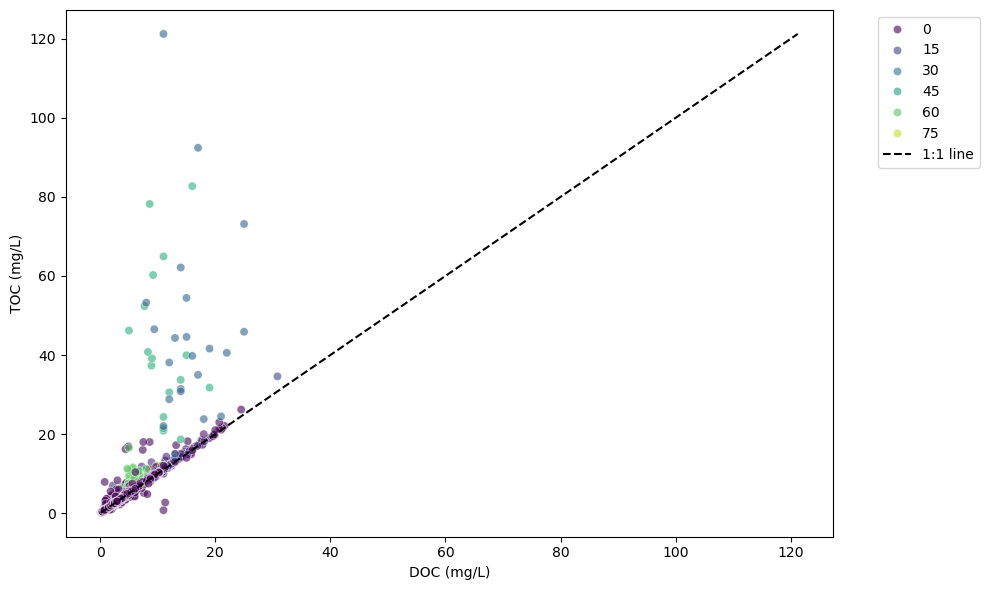

In [90]:
# Quick look at the data

# plt.figure(figsize=(5, 5))
# sns.scatterplot(
#     x='TOC_mg_l',
#     y='DOC_mg_l',
#     data=paired_df,
#     alpha=0.4
# )

# lims = [
#     min(paired_df['TOC_mg_l'].min(), paired_df['TOC_mg_l'].min()),
#     max(paired_df['TOC_mg_l'].max(), paired_df['TOC_mg_l'].max())
# ]
# plt.plot(lims, lims, 'k--')

# plt.xlabel('TOC')
# plt.ylabel('DOC')
# plt.tight_layout()
# plt.show()

# Including agri:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=paired_df,
    x='DOC_mg_l',
    y='TOC_mg_l',
    hue='jordbruk_pct',
    palette='viridis',
    alpha=0.6
)

lims = [
    min(paired_df['TOC_mg_l'].min(), paired_df['DOC_mg_l'].min()),
    max(paired_df['TOC_mg_l'].max(), paired_df['DOC_mg_l'].max())
]

plt.plot(lims, lims, 'k--', label='1:1 line')

plt.ylabel('TOC (mg/L)')
plt.xlabel('DOC (mg/L)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

(0.2, 1.25)

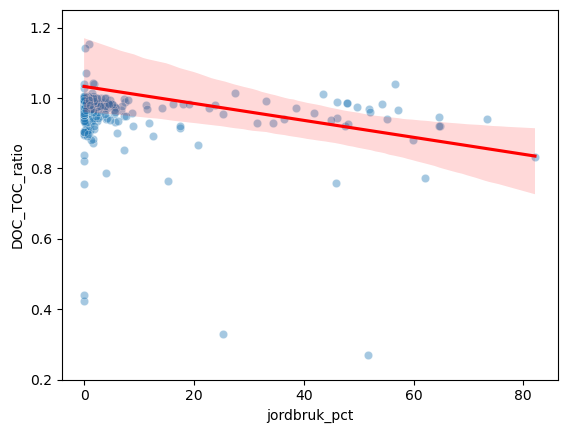

In [85]:
paired_df_sitemeans['DOC_TOC_ratio'] = (
    paired_df_sitemeans['DOC_mg_l'] / paired_df_sitemeans['TOC_mg_l']
)

sns.scatterplot(
    data=paired_df_sitemeans,
    x='jordbruk_pct',
    y='DOC_TOC_ratio',
    alpha=0.4
)

sns.regplot(
    data=paired_df_sitemeans,
    x='jordbruk_pct',
    y='DOC_TOC_ratio',
    scatter=False,
    color='red'
)

plt.ylim(ymax=1.25, ymin=0.2)

Regression for predicting TOC from DOC:

Find that including catchments with over 25% agriculture, then get much worse regression (R2). Same excellent R2 for 25% or 5% agri.

TOC = 0.026 + 1.025 × DOC
R² = 0.973

Use this to predict TOC from DOC in catchments with only DOC data.

Or without the intercept: TOC = 1.030 DOC. i.e. only 3% larger. i.e. 97% of TOC is DOC... Could just simplify and use 1:1!

TOC = 0.026 + 1.025 × DOC
R² = 0.973


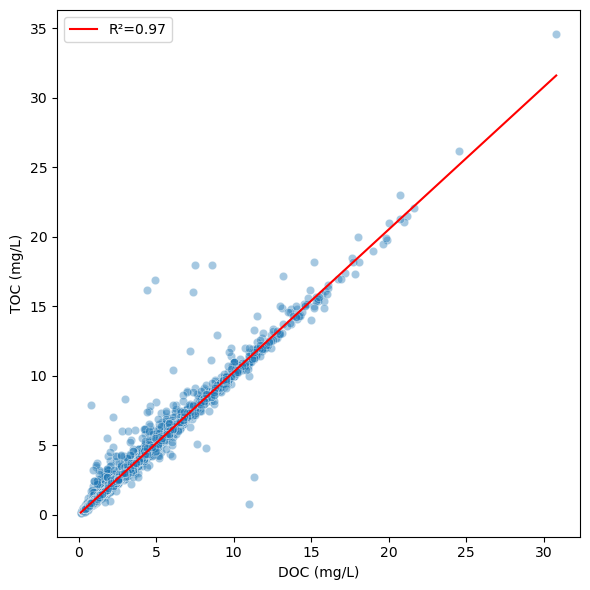

In [98]:
from scipy.stats import linregress

reg_df = paired_df.loc[paired_df['jordbruk_pct'] < 25, :]

# Fit regression
res = linregress(reg_df['DOC_mg_l'], reg_df['TOC_mg_l'])

print(f"TOC = {res.intercept:.3f} + {res.slope:.3f} × DOC")
print(f"R² = {res.rvalue**2:.3f}")

# Plot
plt.figure(figsize=(6, 6))

sns.scatterplot(
    data=reg_df,
    x='DOC_mg_l',
    y='TOC_mg_l',
    alpha=0.4
)

x = np.linspace(reg_df['DOC_mg_l'].min(), reg_df['DOC_mg_l'].max(), 100)
y = res.intercept + res.slope * x

plt.plot(x, y, color='red', label=f'R²={res.rvalue**2:.2f}')

plt.xlabel('DOC (mg/L)')
plt.ylabel('TOC (mg/L)')
plt.legend()
plt.tight_layout()
plt.show()

In [99]:
# Try without fitting constant

# Fit TOC = b * DOC
slope = np.sum(reg_df['DOC_mg_l'] * reg_df['TOC_mg_l']) / np.sum(reg_df['DOC_mg_l']**2)

print(f"TOC = {slope:.3f} × DOC")

# Predictions
reg_df['pred_TOC'] = slope * reg_df['DOC_mg_l']

# RMSE
rmse = np.sqrt(np.mean((reg_df['TOC_mg_l'] - reg_df['pred_TOC'])**2))
print(f"RMSE = {rmse:.2f} mg/L")

TOC = 1.030 × DOC
RMSE = 0.44 mg/L


/tmp/ipykernel_383/619264887.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reg_df['pred_TOC'] = slope * reg_df['DOC_mg_l']


In [100]:
import statsmodels.api as sm

# With intercept
m1 = sm.OLS(reg_df['TOC_mg_l'],
            sm.add_constant(reg_df['DOC_mg_l'])).fit()

# Through origin
m2 = sm.OLS(reg_df['TOC_mg_l'],
            reg_df[['DOC_mg_l']]).fit()

print(m1.summary())
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:               TOC_mg_l   R-squared:                       0.973
Model:                            OLS   Adj. R-squared:                  0.973
Method:                 Least Squares   F-statistic:                 2.713e+05
Date:                Thu, 17 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:15:32   Log-Likelihood:                -4442.7
No. Observations:                7392   AIC:                             8889.
Df Residuals:                    7390   BIC:                             8903.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0255      0.008      3.193      0.0

In [69]:
# # Metadata on number of paired obs

# print(len(paired_df), "DOC–TOC paired observations")
# print(len(paired_df['WaterLocationCode'].unique()), "Sites with paired observations")

# pairs_per_site = (
#     paired_df.groupby('WaterLocationCode')
#     .size()
#     .sort_values(ascending=False)
# )

# pairs_per_site.describe()

In [ ]:
# # Find sites where TOC is a lot more than DOC, i.e. that lie off the 1:1 line
# # in the plot above
# paired_df["DOC_div_TOC"] = paired_df['DOC_mg_l'] / paired_df['TOC_mg_l']

# print(paired_df[var_li].describe())

# # Flag low DOC/TOC points
# threshold = 0.6
# paired_df['low_DOC_flag'] = paired_df['DOC_div_TOC'] < threshold

# # Plot flagged points
# plt.figure(figsize=(6, 6))
# sns.scatterplot(
#     data=paired_df,
#     x='TOC_mg_l',
#     y='DOC_mg_l',
#     hue='low_DOC_flag',
#     palette={False: 'grey', True: 'red'},
#     alpha=0.6
# )

# plt.plot(lims, lims, 'k--', alpha=0.7)

# plt.xlabel('TOC (mg/L)')
# plt.ylabel('DOC (mg/L)')
# plt.tight_layout()
# plt.show()

# flagged_site_codes = paired_df.loc[paired_df["low_DOC_flag"]==True, 'WaterLocationCode'].unique()
# print("Number of flagged sites:", len(flagged_site_codes))

In [ ]:
# # Quick look at sites flagged up
# low_doc_df = paired_df.loc[paired_df['WaterLocationCode'].isin(flagged_site_codes)]
# low_doc_df['ActivityName'].unique()

In [ ]:
# for site in flagged_site_codes:
#     plot_df = paired_df.loc[paired_df['WaterLocationCode'] == site]
#     if len(plot_df) > 2:
#         name = plot_df['Name'].iloc[0]
#         plot_compare_contractors(plot_df, chem_col=['TOC_mg_l', 'DOC_mg_l'], title=f"{site}, {name}", figsize=(15, 4.5)) 

In [ ]:
# for site in flagged_site_codes:
#     plot_df = paired_df.loc[paired_df['WaterLocationCode'] == site]
#     if len(plot_df) > 3:
#         name = plot_df['Name'].iloc[0]
#         plot_compare_contractors(plot_df, chem_col=['DOC_div_TOC'], title=f"{site}, {name}", figsize=(15, 4.5)) 

# Exploring contractor/Lab effects for TOC

Several issues have popped out by accident whilst investigating. Look at these more systematically here:

1. VestfoldLAB positive bias in the period 2016-2020. See limed rivers.
2. NIVA lab negative bias? Especially before 2016 or perhaps mid-2020? See e.g. 028-54640 (Figgjo (Stavanger))

## VestfoldLAB

In [ ]:
# Bjerkreimselva (by Egersund): kalkede laksevassdrag (NIVA until end 2015, then Vestfold lab) and NIVA RID station (parallel data)
sites = ['027-38543']
plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2008-01-01') & (no_outliers_df['Date'] < '2025-09-01')]
plot_df = plot_df.loc[plot_df['WaterLocationCode'].isin(sites)]

plot_compare_contractors(plot_df, chem_col=['TOC_mg_l', 'DOC_mg_l'], title="Bjerkreimselva (limed river & elvetilførsel/elveovervåkingsprogrammet")
# display_df = plot_df.loc[plot_df['WaterLocationCode'] == sites[0]]
# with pd.option_context(
#     "display.max_rows", None,
# ):
#     display(display_df)

In [ ]:
# Pull out other rivers where have nearby stations with parallel data from NIVA & Vestfoldlab
# Vikedalselva
ids = [58868, 38547]
plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2016-01-01') & (no_outliers_df['Date'] < '2020-09-01')]
plot_df = plot_df.loc[plot_df['WaterLocationID'].isin(ids)]

plot_compare_contractors(plot_df, title="Vikedalselva")

# Storelva/Vegårdselva
ids = [90038, 90037, 90036, 90047, 55805, 80526, 59721, 97911, 80527, 80528, 97914, 32157]
plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2016-01-01') & (no_outliers_df['Date'] < '2020-09-01')]
plot_df = plot_df.loc[plot_df['WaterLocationID'].isin(ids)]

plot_compare_contractors(plot_df, chem_col=['TOC_mg_l', 'DOC_mg_l'], title="Storelva")

In [ ]:
# All liming data - plot to look for contractor effect, even if there aren't overlapping data
acid_programmes = ["Forsuringsovervåking", "Tiltaksovervåking i kalkede laksevassdrag"]
river_programmes = ["Elvetilførselsprogrammet", "Elveovervåkingsprogrammet"]

mask_acid = no_outliers_df["ActivityName"].isin(acid_programmes)
mask_river_same_sites = (
    # no_outliers_df["ActivityName"].isin(river_programmes) &
    no_outliers_df["WaterLocationCode"].isin(mask_acid)
)

plot_df = no_outliers_df.loc[mask_acid | mask_river_same_sites].copy()

plot_df = plot_df.loc[
    (no_outliers_df["Date"] > "2013-01-01") & (no_outliers_df["Date"] < "2025-09-01")
]

print("Number of sites:", len(plot_df["WaterLocationCode"].unique()))

# Get a sample of sites for plotting
sample_sites = (
    plot_df["WaterLocationCode"]
    .drop_duplicates()
    .sample(n=50)
)

In [ ]:
# # Plot all 315 sites
# for site_code in plot_df["WaterLocationCode"].unique():
#     data = plot_df.loc[plot_df['WaterLocationCode'] == site_code]
#     if len(data) < 30:
#         continue
#     plot_compare_contractors(data, title=site_code, figsize=(10, 3))

In [ ]:
# Having looked through all limed river monitoring points, there were only a couple of additional ones with
# overlapping Vestfoldlab & other lab data:

site_li = [38514, 32162]

for siteid in site_li:
    plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2018-01-01') & (no_outliers_df['Date'] < '2022-09-01')]
    plot_df = plot_df.loc[plot_df['WaterLocationID'] == siteid]
    site_name = plot_df['Name'].iloc[0]

    plot_compare_contractors(plot_df, chem_col=['TOC_mg_l', 'DOC_mg_l'], title=site_name)

In [ ]:
# Vestfoldlab doesn't look so bad from 2020. Explore whether Vestfold lab is more similar to other labs after 2020
# across a broader range of sites than just the limed rivers (if available)

df_sub = (no_outliers_df.loc[
    (no_outliers_df['Date'] >= '2019-01-01') &
    (no_outliers_df['TOC_mg_l'].notna())]
)

# Identify sites with VestfoldLAB and at least one other contractor
contractors_per_site = (df_sub
    .groupby('WaterLocationCode')['Contractor_simple']
    .nunique()
)
sites_with_multiple_contractors = contractors_per_site[
    contractors_per_site > 1
].index

# Restrict to sites where VestfoldLAB AS is one of them
sites_with_vestfold = (
    df_sub
    .loc[df_sub['Contractor_simple'] == 'VestfoldLAB AS', 'WaterLocationCode']
    .unique()
)

candidate_sites = sorted(
    set(sites_with_multiple_contractors)
    & set(sites_with_vestfold)
)

# Quick summary table
summary = (
    df_sub
    .loc[df_sub['WaterLocationCode'].isin(candidate_sites)]
    .groupby(['WaterLocationCode', 'Contractor_simple'])
    .agg(
        n_samples=('TOC_mg_l', 'size'),
        first_date=('Date', 'min'),
        last_date=('Date', 'max')
    )
    .reset_index()
)

print("Number of sites:", len(summary['WaterLocationCode'].unique()))
# summary.sort_values(['WaterLocationCode', 'Contractor_simple'])

# Check temporal overlap
date_ranges = (
    df_sub
    .loc[df_sub['WaterLocationCode'].isin(candidate_sites)]
    .groupby(['WaterLocationCode', 'Contractor_simple'])
    .agg(start=('Date', 'min'), end=('Date', 'max'))
    .reset_index()
)
# Restrict to candidate sites
date_ranges = date_ranges[
    date_ranges['WaterLocationCode'].isin(candidate_sites)
]


def vestfold_overlap(df_site):
    if 'VestfoldLAB AS' not in df_site['Contractor_simple'].values:
        return False

    v = df_site.loc[df_site['Contractor_simple'] == 'VestfoldLAB AS'].iloc[0]
    others = df_site.loc[df_site['Contractor_simple'] != 'VestfoldLAB AS']

    for _, o in others.iterrows():
        # overlap condition
        if v['start'] <= o['end'] and o['start'] <= v['end']:
            return True

    return False


overlap_flag = (
    date_ranges
    .groupby('WaterLocationCode')
    .apply(vestfold_overlap)
)

overlap_sites = overlap_flag[overlap_flag].index.tolist()
print("Number of sites with good temporal overlap between labs:", len(overlap_sites))

In [ ]:
# # Plot all 66 sites with overlapping data from Vestfold lab and some other lab post 2019
# for siteid in overlap_sites:
#     plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2012-01-01') & (no_outliers_df['Date'] < '2025-09-01')]
#     # plot_df = no_outliers_df.copy()
#     plot_df = plot_df.loc[plot_df['WaterLocationCode'] == siteid]
#     site_name = plot_df['Name'].iloc[0]

#     plot_compare_contractors(plot_df, site_name, figsize=(8, 3))

Not much Vestfold lab data overlapping with other contractors (at least at a single site) after 2020. But overall, agreement looks pretty good then.

Is there actually data from Vestfold lab after 2021? Yes:

In [ ]:
vestfold_late_df = no_outliers_df.loc[
    (no_outliers_df['Contractor_simple'] == 'VestfoldLAB AS') &
    (no_outliers_df['Date'] > '2021-01-01')
]

for col in ['WaterLocationID', 'ActivityName']:
    print(f"Number of {col}s:", len(vestfold_late_df[col].unique()))

In [ ]:
vestfold_late_site_metadata_df = stn_metadata_df.loc[stn_metadata_df['WaterLocationID'].isin(vestfold_late_df['WaterLocationID'].unique())]
vestfold_late_site_metadata_df.describe()

Mostly the vestfold lab data ends in 2023.

In [ ]:
acid_programmes = ["Forsuringsovervåking", "Tiltaksovervåking i kalkede laksevassdrag"]
start_date = '1980-01-01'
end_date = '2025-01-01'

mask_acid = no_outliers_df["ActivityName"].isin(acid_programmes)
acid_sites = (no_outliers_df.loc[mask_acid, "WaterLocationCode"].unique())
limed_riv_df = no_outliers_df[no_outliers_df["WaterLocationCode"].isin(acid_sites)].copy()

limed_riv_df = limed_riv_df.loc[
    (limed_riv_df['Date'] >= start_date) &
    (limed_riv_df['Date'] < end_date)
]
limed_riv_df = limed_riv_df[['WaterLocationCode', 'WaterLocationID', 'Name', 'ActivityName', 'Contractor_simple', 'Date', 'TOC_mg_l']]
limed_riv_df = limed_riv_df.sort_values(['WaterLocationCode', 'Date']).reset_index(drop=True)

limed_riv_df

In [ ]:
# Filter out contractors that have sparse coverage for simpler plotting & visualisation
min_n = 200

contractor_counts = (
    limed_riv_df
    .groupby('Contractor_simple')
    .size()
    .sort_values(ascending=False)
)

print(contractor_counts)

good_contractors = contractor_counts[contractor_counts >= min_n].index

limed_riv_df['Contractors_for_plot'] = limed_riv_df['Contractor_simple']
limed_riv_df.loc[
    ~limed_riv_df['Contractor_simple'].isin(good_contractors),
    'Contractors_for_plot'
] = 'Other (sparse)'

# limed_riv_df_filt = limed_riv_df[
#     limed_riv_df['Contractor_simple'].isin(good_contractors)
# ].copy()

In [ ]:
limed_riv_df['Year'] = limed_riv_df['Date'].dt.year

annual = (
    limed_riv_df
    .groupby(['Year', 'Contractors_for_plot'])['TOC_mg_l']
    .agg(['median', 'count'])
    .reset_index()
)

plt.figure(figsize=(10, 5))

for contractor, d in annual.groupby('Contractors_for_plot'):
    # Optional: only plot if reasonable sample size
    d = d[d['count'] >= 10]
    plt.plot(d['Year'], d['median'], marker='o', label=contractor, lw=0.3, ms=6)

plt.ylabel('Median TOC (mg/L)')
plt.title('TOC – acidification programmes (yearly median)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Just plot annual medians (remove contractor grouping), to see if there are step changes when contractor changed
start_year = 1985
end_year   = 2025

n_years = end_year - start_year + 1
min_years = int(0.9 * n_years)

slice_limed_riv_df = limed_riv_df.loc[
    (limed_riv_df['Date'] > f'{start_year}') &
    (limed_riv_df['Date'] < f'{end_year}')
]

site_year_counts = (
    slice_limed_riv_df
    .groupby('WaterLocationCode')['Year']
    .nunique()
)

good_sites = site_year_counts[
    site_year_counts >= min_years
].index

limed_riv_df_balanced = slice_limed_riv_df[
    slice_limed_riv_df['WaterLocationCode'].isin(good_sites)
].copy()

print(len(limed_riv_df['WaterLocationCode'].unique()))
print(len(limed_riv_df_balanced['WaterLocationCode'].unique()))
print(
    limed_riv_df_balanced
    .groupby('WaterLocationCode')['Year']
    .agg(['min', 'max', 'nunique'])
    .describe()
)


# Make df of annual medians for selected sites
annual = (
    limed_riv_df_balanced
    .groupby('Year')['TOC_mg_l']
    .agg(['median', 'count'])
    .reset_index()
)
# Require a minimum number of samples per year
annual = annual[annual['count'] >= 200]

# For stacked bar chart: contractor proportions by year

# Count samples per year × contractor
counts = (
    limed_riv_df_balanced
    .groupby(['Year', 'Contractor_simple'])
    .size()
    .reset_index(name='n')
)

top_n = 4
top_contractors = (
    counts
    .groupby('Contractor_simple')['n']
    .sum()
    .sort_values(ascending=False)
    .head(top_n)
    .index
)
counts['Contractor_plot'] = counts['Contractor_simple']
counts.loc[
    ~counts['Contractor_simple'].isin(top_contractors),
    'Contractor_plot'
] = 'Other'

# Compute annual proportions per contractor
annual_props = (
    counts
    .groupby(['Year', 'Contractor_plot'])['n']
    .sum()
    .reset_index()
)

annual_props['prop'] = (
    annual_props
    .groupby('Year')['n']
    .transform(lambda x: x / x.sum())
)

# Plot stacked bars
pivot_props = (
    annual_props
    .pivot(index='Year', columns='Contractor_plot', values='prop')
    .fillna(0)
)

# Plot

fig, (ax1, ax2) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 7),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05}
)

# Time series of medians
ax1.plot(
    annual['Year'],
    annual['median'],
    marker='o',
    lw=2,
    ms=6,
    color='black'
)

ax1.set_ylabel('Median TOC (mg/L)')
ax1.set_title(
    'TOC – acidification programmes\n'
    'Annual medians (balanced long‑term sites) and contractor composition'
)
ax1.grid(True, alpha=0.3)

# Stacked bars
years = pivot_props.index.values
bottom = np.zeros(len(years))

for contractor in pivot_props.columns:
    ax2.bar(
        years,
        pivot_props[contractor].values,
        bottom=bottom,
        width=0.9,
        label=contractor
    )
    bottom += pivot_props[contractor].values


ax2.set_ylabel('Proportion')
ax2.set_xlabel('Year')
ax2.grid(False)

# Make the bars visually lighter
for p in ax2.patches:
    p.set_linewidth(0)

ax2.legend(
    title='Contractor',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax2.set_xlim(start_year - 0.5, end_year + 0.5)

plt.show()

**Summary so far**

Evidence:
- Individual time series plots showing TOC values are often high compared to NIVA data taken at the same time. NIVA data match Eurofins data after 2020, suggesting VestfoldLab is biased high rather than NIVA being biased low? BUT - see discussion below about possible NIVA under-detection of TOC, perhaps particularly in the period 2018 - spring 2020 (not conclusive, but a suggestion of this).
- Time series plots without NIVA data, where 2016-2020 are often high, corresponding to the period when VestfoldLab had the contract
- Time series plot of site median over all sites (27) with data for most of the period 1985-2025: 2016, 2017 and 2019 were the highest TOC years on record, and correspond with VestfoldLab taking over about a quarter of sites.
- Still to investigate: TOC data from 2024, which was also very high. By then, it was NIVA and Eurofins.

But an alternative plausible explanation is that NIVA-lab under-detected TOC, particularly in the period pre mid-2020.

For the ML:
- Keep all data but add lab in as a variable? Issue: only have contractor data, not lab data. So it's messier than it should be. Would take a lot of work to figure out which labs had actually done the analyses for all contractors. Plus this is the wrong way of thinking about it - contractor shouldn't be a predictor variable
- Manually clean and remove labs thought to be dodgy. But: lab often not recorded, plus we don't know which lab is closer to the "truth"
- Keep all data and explore residuals as a function of contractor. But if it's shown to be an issue, not sure what to do...

## NIVA lab biased down? Step change (increase) in NIVA data over time?

In [ ]:
df_sub = (df.loc[
    (df['Date'] >= '1985-01-01') &
    (df['TOC_mg_l'].notna())]
)

# Identify sites with NIVA lab and at least one other contractor
contractors_per_site = (df_sub
    .groupby('WaterLocationCode')['Contractor_simple']
    .nunique()
)
sites_with_multiple_contractors = contractors_per_site[
    contractors_per_site > 1
].index

# Restrict to sites where NIVA is one of them
sites_with_vestfold = (
    df_sub
    .loc[df_sub['Contractor_simple'] == 'NIVA', 'WaterLocationCode']
    .unique()
)

candidate_sites = sorted(
    set(sites_with_multiple_contractors)
    & set(sites_with_vestfold)
)

# Quick summary table
summary = (
    df_sub
    .loc[df_sub['WaterLocationCode'].isin(candidate_sites)]
    .groupby(['WaterLocationCode', 'Contractor_simple'])
    .agg(
        n_samples=('TOC_mg_l', 'size'),
        first_date=('Date', 'min'),
        last_date=('Date', 'max')
    )
    .reset_index()
)

print("Number of sites:", len(summary['WaterLocationCode'].unique()))
# summary.sort_values(['WaterLocationCode', 'Contractor_simple'])

# Check temporal overlap
date_ranges = (
    df_sub
    .loc[df_sub['WaterLocationCode'].isin(candidate_sites)]
    .groupby(['WaterLocationCode', 'Contractor_simple'])
    .agg(start=('Date', 'min'), end=('Date', 'max'))
    .reset_index()
)
# Restrict to candidate sites
date_ranges = date_ranges[
    date_ranges['WaterLocationCode'].isin(candidate_sites)
]


def contractor_overlap(df_site, contractor="NIVA"):
    if contractor not in df_site['Contractor_simple'].values:
        return False

    v = df_site.loc[df_site['Contractor_simple'] == contractor].iloc[0]
    others = df_site.loc[df_site['Contractor_simple'] != contractor]

    for _, o in others.iterrows():
        # overlap condition
        if v['start'] <= o['end'] and o['start'] <= v['end']:
            return True

    return False


overlap_flag = (
    date_ranges
    .groupby('WaterLocationCode')
    .apply(contractor_overlap)
)

overlap_sites = overlap_flag[overlap_flag].index.tolist()
print("Number of sites with good temporal overlap between labs:", len(overlap_sites))

In [ ]:
# # Plot all sites with overlapping data from NIVA lab and some other lab
# for siteid in overlap_sites:
#     plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '1985-01-01') & (no_outliers_df['Date'] < '2025-09-01')].copy()
#     plot_df = plot_df.loc[plot_df['WaterLocationCode'] == siteid]
#     if len(plot_df) < 1:
#         continue
#     site_name = plot_df['Name'].iloc[0]

#     plot_compare_contractors(plot_df, title=siteid, figsize=(12, 3))

In [ ]:
# Zoom in on some interesting sites with overlapping data from different labs
site_li = ['006-51733']
for siteid in site_li:
    plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2014-01-01') & (no_outliers_df['Date'] < '2023-01-01')].copy()
    plot_df = plot_df.loc[plot_df['WaterLocationCode'] == siteid]
    if len(plot_df)<1:
        continue
    site_name = plot_df['Name'].iloc[0]

    plot_compare_contractors(plot_df, title=siteid, figsize=(20, 6))

In [ ]:
# Zoom in on some interesting sites
site_li = ['012-38512']
for siteid in site_li:
    plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2013-01-01') & (no_outliers_df['Date'] < '2024-01-01')].copy()
    plot_df = plot_df.loc[plot_df['WaterLocationCode'] == siteid]
    if len(plot_df)<1:
        continue
    site_name = plot_df['Name'].iloc[0]

    plot_compare_contractors(plot_df, title=siteid, figsize=(20, 6))

In [ ]:
# Figgjo, Jæren. Bielva & tiltaksovervåking
site_li = ['028-54640']
for siteid in site_li:
    plot_df = no_outliers_df.loc[(no_outliers_df['Date'] > '2000-01-01') & (no_outliers_df['Date'] < '2017-01-01')].copy()
    plot_df = plot_df.loc[plot_df['WaterLocationCode'] == siteid]
    if len(plot_df)<1:
        continue
    site_name = plot_df['Name'].iloc[0]

    plot_compare_contractors(plot_df, title="Figgjo, Jæren (bielve)", figsize=(20, 6))

In summary, in the few sites where there is some decent overlap between NIVA data and data from other labs, NIVA always seems to record lower TOC concentrations than other labs. This holds regardless of who the other lab is. It fits my broader impression from looking at more time series - NIVA concs are generally lower than other contractors.

If site 51733 is to be believed, then this under-detection might have been more pronounced in the period spring 2018 to spring 2020 (incl.)

### Explore interannual variability in NIVA data

At some referanseelver sites, there seems to be a see-sawing across years with low values in 2018, high in 2020, low again in 2020, high in 2024. See e.g. 015-65432, 008-95452 (and plenty others). Explore here whether this is systematic, implying for example that NIVA-lab was under-detecting TOC in 2018 (or over-detecting in 2020).

Result:
* Annual boxplot across all sites show that for even year sampled sites, 2020 had overall higher concs than 2018, 2022 and 2024. For odd-sampled sites, there is no clear sdifference across years.
* Individual time series show that this odd step-change issue seen at some sites is visible at a few sites, but at many sites it is absent and things look fine.
* Overall, I am a bit suspicious of NIVA data from 2018 (low-bias?), but not enough evidence from the referanseelver to conclude this is the case when you look beyond a few specific sites.

#### Referanseelver

In [ ]:
# Referanseelver: low 2018 and 2022, systematically higher 2020 and 2024 in a couple of rivs. Seen across program?
sites = ['015-65432']   # Kjørstadelva, referanseelver
plot_df_trunc = no_outliers_df.loc[(no_outliers_df['Date'] > '1980') & (no_outliers_df['Date'] < '2025')]
for site in sites:
    plot_df = plot_df_trunc.loc[plot_df_trunc['WaterLocationCode'] == site]
    plot_compare_contractors(plot_df, title=site, figsize=(15, 4.5))
plot_df.head()

In [ ]:
refelver_df = no_outliers_df.loc[no_outliers_df['ActivityName'] == 'Referanseelver'].copy()
refelver_df['Year'] = refelver_df['Date'].dt.year

print(len(refelver_df['WaterLocationCode'].unique()))

# Make df of annual medians for selected sites
annual = (
    refelver_df
    .groupby('Year')['TOC_mg_l']
    .agg(['median', 'count'])
    .reset_index()
)


# Plot
fig, ax1 = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(12, 4)
)

# Time series of medians
ax1.plot(
    annual['Year'],
    annual['median'],
    marker='o',
    lw=2,
    ms=6,
    color='black'
)

ax1.set_ylabel('Median TOC (mg/L)')
ax1.set_title(
    'TOC – referanseelver programmes\n'
    'Annual medians'
)
ax1.grid(True, alpha=0.3)
ax1.set_xlabel('Year')
# ax2.grid(False)

plt.show()

# -------------------------------
# Plot annual boxplots

# Prepare data for boxplots: one array per year
years = sorted(refelver_df['Year'].unique())
data_by_year = [
    refelver_df.loc[refelver_df['Year'] == yr, 'TOC_mg_l'].dropna()
    for yr in years
]

# Plot
fig, ax = plt.subplots(figsize=(6, 4))

ax.boxplot(
    data_by_year,
    positions=range(len(years)),
    widths=0.6,
    showfliers=False  # keep False since you already removed outliers
)

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, rotation=45)
ax.set_ylabel('TOC (mg/L)')

ax.set_title(
    'Referanseelver, annual distributions of TOC conc'
)

ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# # Make some time series plots
# refelver_ids = refelver_df['WaterLocationCode'].unique()

# # plot_sites(refelver_df, refelver_ids[:4], 1, sharex=True, gridon=False)
# for site in refelver_ids[60:80]:
#     plot_df = refelver_df.loc[refelver_df['WaterLocationCode'] == site]
#     if len(plot_df['TOC_mg_l'].dropna()) < 24:
#         continue

#     plot_compare_contractors(plot_df, title=site, figsize=(10, 3))

#### Elvetilførsels- og -overvåkings programs

In [ ]:
rid_df = no_outliers_df.loc[no_outliers_df['ActivityName'].isin(['Elvetilførselsprogrammet', 'Elveovervåkingsprogrammet'])].copy()
rid_df['Year'] = rid_df['Date'].dt.year

print(len(rid_df['WaterLocationCode'].unique()))

# Make df of annual medians for selected sites
annual = (
    rid_df
    .groupby('Year')['TOC_mg_l']
    .agg(['median', 'count'])
    .reset_index()
)


# Plot
fig, ax1 = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(12, 4)
)

# Time series of medians
ax1.plot(
    annual['Year'],
    annual['median'],
    marker='o',
    lw=2,
    ms=6,
    color='black'
)

ax1.set_ylabel('Median TOC (mg/L)')
ax1.set_title(
    'TOC – elveovervåking programmes\n'
    'Annual medians'
)
ax1.grid(True, alpha=0.3)
ax1.set_xlabel('Year')
# ax2.grid(False)

plt.show()

# -------------------------------
# Plot annual boxplots

# Prepare data for boxplots: one array per year
years = sorted(rid_df['Year'].unique())
data_by_year = [
    rid_df.loc[rid_df['Year'] == yr, 'TOC_mg_l'].dropna()
    for yr in years
]

# Plot
fig, ax = plt.subplots(figsize=(10, 4))

ax.boxplot(
    data_by_year,
    positions=range(len(years)),
    widths=0.6,
    showfliers=False  # keep False since you already removed outliers
)

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, rotation=45)
ax.set_ylabel('TOC (mg/L)')

ax.set_title(
    'Elveovervåking, annual distributions of TOC conc'
)

ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# # Make some time series plots
# rid_ids = rid_df['WaterLocationCode'].unique()

# # plot_sites(refelver_df, refelver_ids[:4], 1, sharex=True, gridon=False)
# for site in rid_ids:
#     plot_df = rid_df.loc[rid_df['WaterLocationCode'] == site]
#     site_name = plot_df['Name'].iloc[0]
#     if len(plot_df['TOC_mg_l'].dropna()) < 24:
#         continue

#     plot_compare_contractors(plot_df, title=f"{site}, {site_name}", figsize=(10, 3))

# Unused, trying things out

In [ ]:
# def estimate_local_precision(df, chem_col, site_col="WaterLocationID", date_col="Date", window=20):
#     df = df.sort_values([site_col, date_col]).copy()

#     # Successive absolute differences within each site
#     df["diff"] = df.groupby(site_col)[chem_col].diff().abs()

#     # Apply a rolling window, and take the minimum nonzero difference
#     # within that window. This minimum is an estimate of the reporting resolution.
#     df["local_precision"] = (
#         df.groupby(site_col)["diff"]
#           .transform(lambda x: x.replace(0, np.nan)  # Ignore diffs of zero (not precision info)
#                                .rolling(window=window, min_periods=10)
#                                .min())
#     )

#     return df#.drop(columns=["diff"])


# chem_col = "TOC_mg_l"
# flat_df = estimate_local_precision(out_df, chem_col, window=20)

# # Look for periods of bad precision
# flat_df["precision_bad"] = flat_df["local_precision"] >= 1.0  # mg/l
# # Add colour column
# flat_df[f"{chem_col}_precision_colour"] = flat_df["precision_bad"].map({True: "r", False: "k"})

# # Sites for plotting
# low_precision_sites = flat_df.loc[flat_df["precision_bad"] == True, 'WaterLocationCode'].unique()
# print(len(low_precision_sites))

# flat_df.head()

In [ ]:
# def flag_flat_runs(df, chem_col, site_col="WaterLocationID", 
#                         date_col="Date", min_n=3, min_days=7):

#     df = df.sort_values([site_col, date_col]).copy()

#     # Identify beginnings of runs (value change or site change)
#     value_change = df[chem_col].ne(df[chem_col].shift())
#     site_change = df[site_col].ne(df[site_col].shift())

#     new_group = (value_change | site_change)

#     # Run-id: vectorised cumulative sum
#     df["run_id"] = new_group.cumsum()

#     # Group once by (site, run)
#     g = df.groupby([site_col, "run_id"])

#     stats = g.agg(
#         n_points=(chem_col, "count"),
#         start_date=(date_col, "min"),
#         end_date=(date_col, "max")
#     )

#     stats["duration_days"] = (stats["end_date"] - stats["start_date"]).dt.days

#     # Identify bad runs
#     bad_ids = stats.query(
#         "n_points >= @min_n and duration_days >= @min_days"
#     ).index

#     # Create a boolean flag column
#     df[f"{chem_col}_flat"] = df.set_index([site_col, "run_id"]).index.isin(bad_ids)

#     # Add colour column
#     df[f"{chem_col}_flat_colour"] = df[f"{chem_col}_flat"].map({True: "r", False: "k"})

#     return df.drop(columns=["run_id"]), bad_ids


# flat_df, bad_runs = flag_flat_runs(out_df, "TOC_mg_l", min_n=3, min_days=90)
# flat_df.head()